# Prop Firm Challenge — Monte Carlo Pass Rate & Payout Estimator
### Apex 50K EOD Trailing Drawdown (4.0 rules)

Upload your MultiCharts report (.xlsx) as exported and estimate your probability of passing the Apex 50K evaluation, and what the funded account is worth, via day-based Monte Carlo simulation.

**Part 1 — Evaluation (Cells 1-10):** trade stats, OOS split, pass probability, position size sweep

**Part 2 — Funded Account (Cells 11-16):** payout rules, full 6-payout account lifetime, the size that maximizes total extraction

*Simulations resample your backtest; live results degrade. Rules reflect Apex 4.0 — verify against your dashboard.

Not a Financial Advice*

---

In [ ]:
# =========================================================
# CELL 1: UPLOAD YOUR TRADE FILE (CSV or MultiCharts .xlsx)
# =========================================================

from google.colab import files
import os

uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No file uploaded. Please re-run this cell and select your file.")

if len(uploaded) > 1:
    print(f"⚠️  {len(uploaded)} files uploaded - using only the first: '{list(uploaded.keys())[0]}'")

FILENAME = list(uploaded.keys())[0]
_size = os.path.getsize(FILENAME)
if _size == 0:
    raise RuntimeError(f"'{FILENAME}' is empty (0 bytes). Re-export it and upload again.")

print(f"\n✅ Loaded: {FILENAME} ({_size:,} bytes)")

if FILENAME.lower().endswith((".xlsx", ".xlsm", ".xls")):
    # Peek at the workbook so problems are obvious immediately
    try:
        import pandas as _pd
        _sheets = _pd.ExcelFile(FILENAME).sheet_names
        print(f"   Excel workbook with sheets: {_sheets}")
        if not any(s.strip().lower() == "list of trades" for s in _sheets):
            print("   ⚠️  No 'List of Trades' sheet found - CELL 3 will fail unless "
                  "this is a plain one-sheet trade table.")
        else:
            print("   'List of Trades' sheet found - CELL 3 will read it directly "
                  "(no manual prep needed).")
    except Exception as _e:
        print(f"   (Could not preview the workbook: {_e})")
else:
    # CSV: peek at the header line
    try:
        with open(FILENAME, "rb") as _fh:
            _first = _fh.readline().decode("utf-8-sig", errors="replace").rstrip("\r\n")
        _delim = max([";", ",", "\t", "|"], key=_first.count)
        _ncols = _first.count(_delim) + 1
        _shown = _first if len(_first) <= 160 else _first[:160] + " …"
        print(f"   Delimiter looks like {_delim!r}  ({_ncols} columns)")
        print(f"   Header: {_shown}")
    except Exception as _e:
        print(f"   (Could not preview the header: {_e})")

print("\n➡️  Now run CELL 2 (settings), then CELL 3 (loads & validates the data).")

Saving NQ DriftPullback Trades.xlsx to NQ DriftPullback Trades.xlsx

✅ Loaded: NQ DriftPullback Trades.xlsx (800,097 bytes)
   Excel workbook with sheets: ['Strategy Analysis', 'List of Trades', 'Trade Analysis', 'Periodical Analysis', 'Settings']
   'List of Trades' sheet found - CELL 3 will read it directly (no manual prep needed).

➡️  Now run CELL 2 (settings), then CELL 3 (loads & validates the data).


In [ ]:
# =========================================================
# CELL 2: USER INPUTS — Edit these to match your setup
# =========================================================

# --- Instrument labels (display only - no effect on any calculation) ---
INSTRUMENT     = "NQ"    # printed in the report headers so a result file says
                         # which instrument it came from
MINI_LABEL     = "MINI"  # what one unit of NUM_CONTRACTS is called
MICRO_LABEL    = "MICRO" # what the micro-equivalent column is called
MICRO_PER_MINI = 10      # micros per mini. 10 for NQ/ES/YM/RTY/CL/GC/6E,
                         # but NOT universal - check your contract before
                         # trusting the micro column.


# --- Source data contract size ---
# Every per-contract number in this notebook assumes it knows how many
# contracts the source export was run at. If a strategy was exported at 2
# contracts and that goes unnoticed, its P&L enters the book at double
# weight and the whole mix/size optimisation is distorted.
# The loader now DETECTS the size instead of assuming it:
# constant across the file -> normalised by that constant, reported
# varying within the file  -> ambiguous, see the flag below
ALLOW_VARIABLE_CONTRACTS = False   # True: normalise per trade and warn. Only do
                                   # this if the strategy's own position sizing
                                   # is something you want divided back out.

# --- Resampling ---
# BOOTSTRAP_BLOCK = 1 draws each simulated day independently from the history.
# That breaks up runs: a historical week of consecutive losses is scattered
# across the simulation instead of arriving together. A trailing drawdown is
# killed by consecutive bad days, so the iid answer understates regime risk.
# BOOTSTRAP_BLOCK = 5 or 10 draws contiguous stretches instead (moving-block
# bootstrap), keeping runs intact. Run all three: a size that only looks good
# at block 1 is not a size you want.
BOOTSTRAP_BLOCK = 1

# --- Holdout for the selection step ---
# Everything this notebook picks (the size, and in MultiStrats the mix) is a
# choice made from the data. Measuring that choice on the same data it was
# made from flatters it. VALIDATION_SPLIT holds out the LAST share of the
# history: selection runs on the earlier part, the headline numbers are
# reported on the held-out part, which the selection never saw.
# 0.0 disables the holdout - then every number is in-sample and the notebook
# says so.
VALIDATION_SPLIT = 0.30

# --- Position sizing ---
NUM_CONTRACTS = 1               # MINI-equivalent contracts (e.g. 1.5 = 15 micros)

# --- Per-trade cost assumptions ---
RISK_PER_CONTRACT = 1_500.0       # Dollar risk per 1 MINI contract per trade
COMMISSION_PER_CONTRACT = 2.25    # Round-trip commission per MINI contract
SLIPPAGE_PER_CONTRACT = 5.0       # Estimated slippage per MINI contract

# --- Simulation parameters ---
PROP_MC_SIMS = 20_000             # Main simulation count
SWEEP_SIMS   = 5_000              # Sims per sweep point (faster)
# --- Evaluation window ---
# Apex gives 30 CONSECUTIVE CALENDAR DAYS from purchase, not a number of
# trading days. How many trading days that is depends on the weekday you start
# on: 30 days spans four weekends, so it is 22 weekdays from a Monday start,
# 21 from a Friday or Sunday, 20 from a Saturday. Holidays sit inside that
# window too and are already in the day grid as zero-trade days.
# EVAL_WINDOW = "calendar" draws the deadline per simulated evaluation from the
#   real calendar of your data, so the mix of 20/21/22-day windows comes out
#   right instead of being averaged away.
# EVAL_WINDOW = "fixed" uses MAX_TRADING_DAYS for every run - only pick this if
#   you specifically want a fixed-length window.
EVAL_WINDOW = "calendar"
EVAL_WINDOW_CALENDAR_DAYS = 30    # Apex 50K EOD access period
MAX_TRADING_DAYS = 21             # only used when EVAL_WINDOW = "fixed"

# --- Out-of-sample split ---
OOS_START_DATE = "2023-01-01"    # e.g. "2024-06-01" -> stats/simulation use trades from this date; None = full sample

# --- Position size sweep (MINI-equivalent) ---
SWEEP_CONTRACTS = [0.3, 0.5, 0.7, 1.0, 1.1, 1.3, 1.5, 1.7, 2.0]

SEED = 42
print("✅ Inputs set.")


✅ Inputs set.


In [ ]:
# =========================================================
# CELL 3: IMPORTS, LOAD & VALIDATE DATA
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from dataclasses import dataclass
from typing import Dict
from io import StringIO
import re

# ── Style setup ──────────────────────────────────────────
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#cccccc",
    "axes.labelcolor": "#222222", "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.grid": True, "grid.color": "#e0e0e0", "grid.linewidth": 0.5, "text.color": "#222222",
    "xtick.color": "#444444", "ytick.color": "#444444", "font.family": "sans-serif",
    "font.size": 10, "legend.facecolor": "white", "legend.edgecolor": "#cccccc",
    "legend.fontsize": 9, "figure.dpi": 120,
})

# ── Day-first (EU) vs month-first (US) auto-detection, shared by both loaders ──
# ── Day-first (EU) vs month-first (US) auto-detection, shared by both loaders ──
def _dayfirst(series):
    """Auto-detect day-first (EU) vs month-first (US) from the actual values.
    Falls back to the separator: dotted dates → EU day-first, else month-first."""
    txt = series.dropna().astype(str)
    m = txt.str.extract(r"^\s*(\d{1,4})\D+(\d{1,2})")
    a = pd.to_numeric(m[0], errors="coerce")
    b = pd.to_numeric(m[1], errors="coerce")
    if (a > 31).any():                       # first field is a year (ISO) → irrelevant
        return False
    if (a > 12).any():                       # first field must be a day → EU
        return True
    if (b > 12).any():                       # second field must be a day → US month-first
        return False
    return bool(txt.str.contains(r"\.", regex=True).any())   # ambiguous: dotted → EU

# ── Read a raw MultiCharts .xlsx report directly ─────────────────────────
def _read_multicharts_xlsx(path):
    xls = pd.ExcelFile(path)
    sheet = next((s for s in xls.sheet_names if s.strip().lower() == "list of trades"), None)
    if sheet is None:
        if len(xls.sheet_names) == 1:
            sheet = xls.sheet_names[0]
            print(f"ℹ️  No 'List of Trades' sheet - using the only sheet: {sheet!r}")
        else:
            raise RuntimeError(
                "❌ Excel file has no 'List of Trades' sheet.\n"
                f"   Sheets found: {xls.sheet_names}\n"
                "   Export the full Strategy Performance Report from MultiCharts.")

    # Find the header row dynamically (usually row 3) instead of hardcoding it
    probe = pd.read_excel(xls, sheet_name=sheet, header=None, nrows=15)
    hdr = None
    for i, row in probe.iterrows():
        cells = [str(v).strip().lower() for v in row.tolist()]
        if any(c in ("trade #", "trade#", "trade_id") for c in cells):
            hdr = i
            break
    if hdr is None:
        raise RuntimeError(
            "❌ Could not find the header row (looked for 'Trade #') in the first "
            f"15 rows of sheet {sheet!r}. Is this a MultiCharts List of Trades export?")

    d = pd.read_excel(xls, sheet_name=sheet, header=hdr)
    d.columns = d.columns.astype(str).str.strip().str.lower()
    print(f"ℹ️  MultiCharts .xlsx detected - sheet {sheet!r}, header on row {hdr + 1}, "
          f"{len(d)} raw rows.")

    # Keep only entry rows (Trade # present). Exit rows have a blank Trade #
    # and no P&L. This replaces your manual 'delete blank Trade # rows' step.
    tid = next((c for c in d.columns if c in ("trade #", "trade#", "trade_id")), None)
    if tid is not None:
        n0 = len(d)
        d = d[pd.to_numeric(d[tid], errors="coerce").notna()].copy()
        print(f"ℹ️  Kept {len(d)} entry rows (dropped {n0 - len(d)} exit/blank rows).")

    # Build ONE 'datetime' column here. In these exports 'date' usually already
    # holds the full timestamp and 'time' duplicates it; if 'date' is date-only,
    # the clock time is taken from 'time'. Dropping date/time afterwards stops
    # the downstream logic from adding the time twice.
    if "date" in d.columns:
        # Excel usually stores these as true datetimes (locale-independent).
        # If a locale exported them as TEXT, detect day-first vs month-first
        # from the data itself instead of trusting pandas' US default.
        _is_str = d["date"].map(lambda v: isinstance(v, str)).mean() > 0.5
        _dayf = _dayfirst(d["date"]) if _is_str else False
        if _is_str:
            print(f"ℹ️  Dates are text strings → parsing "
                  f"{'day' if _dayf else 'month'}-first (auto-detected).")
        dt = pd.to_datetime(d["date"], dayfirst=_dayf, errors="coerce")
        if "time" in d.columns:
            tm = pd.to_datetime(d["time"], dayfirst=_dayf, errors="coerce")
            _date_only = dt.notna() & (dt == dt.dt.normalize())
            _has_clock = tm.notna() & (tm != tm.dt.normalize())
            _add = _date_only & _has_clock
            if _add.any():
                dt = dt.where(~_add, dt.dt.normalize() + (tm - tm.dt.normalize()))
        d["datetime"] = dt
        d = d.drop(columns=[c for c in ("date", "time") if c in d.columns])

    return d

# ── Robust read: BOM, delimiter auto-detect, junk pre-header rows ─────────
def _read_table(path):
    if path.lower().endswith((".xlsx", ".xlsm", ".xls")):
        return _read_multicharts_xlsx(path)
    with open(path, "rb") as fh:
        text = fh.read().decode("utf-8-sig", errors="replace")
    lines = text.splitlines()
    hdr = next((i for i, l in enumerate(lines) if "trade_id" in l.lower()), None)
    if hdr is None:                                   # fall back to first non-empty row
        hdr = next((i for i, l in enumerate(lines) if l.strip()), 0)
    body = lines[hdr:]

    # Some exports, and any CSV whose rows all landed in column A while it
    # was edited in Excel, wrap EVERY row in quotes:  "a,b,c,...,z"
    # The whole line is then ONE quoted field, so you get a single column
    # whose *name* is the entire header line. Unwrap before parsing.
    def _unwrap(rows):
        return [(s[1:-1].replace('""', '"')
                 if len(s) >= 2 and s.startswith('"') and s.endswith('"') else s)
                for s in (r.strip() for r in rows)]

    def _parse(rows):
        head = rows[0] if rows else ""
        dl = max([";", ",", "\t", "|"], key=head.count)
        return pd.read_csv(StringIO("\n".join(rows)), sep=dl, engine="python")

    _h = body[0].strip() if body else ""
    _wrapped = _h.startswith('"') and _h.endswith('"') and _h.count('"') == 2
    if _wrapped:
        body = _unwrap(body)
    d = _parse(body)

    # Safety net: if it STILL came out as ONE column whose name is a whole
    # header line, the quoting was shaped differently than expected - unwrap
    # and try once more rather than failing.
    if d.shape[1] == 1 and max(str(d.columns[0]).count(c) for c in ",;\t|") >= 3:
        _retry = _unwrap(body)
        if _retry != body:
            _d2 = _parse(_retry)
            if _d2.shape[1] > 1:
                d, _wrapped = _d2, True
    if _wrapped:
        print("ℹ️  Every row was wrapped in quotes (normal after editing in Excel) - unwrapped.")
    d.columns = d.columns.astype(str).str.strip().str.lower()
    return d

try:
    df = _read_table(FILENAME)
except Exception as e:
    raise RuntimeError(f"❌ Could not read '{FILENAME}'.\n   Error: {e}\n"
                       f"   Make sure it's a valid CSV or Excel file.")

print(f"Columns found: {df.columns.tolist()}")
print(f"Rows loaded:   {len(df)}")
if len(df) == 0:
    raise RuntimeError("❌ File is empty - no data rows found.")

# ── Drop duplicated/garbled columns some exports append ──────────────────
_junk = [c for c in df.columns if str(c).count(",") >= 3]
if _junk and len(_junk) < len(df.columns):
    df = df.drop(columns=_junk)
    print(f"ℹ️  Dropped {len(_junk)} duplicated/garbled column(s) appended by the export.")
elif _junk:
    raise RuntimeError(
        "❌ This file could not be split into columns - each row is one long text field.\n"
        f"   The single column is named: {str(df.columns[0])[:70]}…\n\n"
        "   This means the whole row sat in column A in Excel. To split it there:\n"
        "     select column A → Data → Text to Columns → Delimited → Next →\n"
        "     tick BOTH Comma and Semicolon → Finish → save as CSV and re-upload.\n"
        "   Alternatively upload the .xlsx report and this cell will convert it for you.")

# ── Auto-map common export headers to the names this notebook expects ────
_ALIASES = {
    "trade_id":   ["trade #", "trade#", "trade no", "trade number"],
    "order_id":   ["order #", "order#", "order no"],
    "excel_date": ["date", "entry date", "date/time"],
    "excel_time": ["time", "entry time"],
    "price":      ["entry price", "fill price"],
    "contracts":  ["qty", "quantity", "size", "shares", "lots", "position size"],
    "profit_usd": ["profit ($)", "profit($)", "profit", "p/l", "pnl",
                   "net profit", "profit (usd)", "profit usd", "p&l"],
}
_ren = {}
for _tgt, _aliases in _ALIASES.items():
    if _tgt in df.columns:
        continue                                   # already correct
    for _a in _aliases:
        if _a in df.columns and _a not in _ren:
            _ren[_a] = _tgt
            break
if _ren:
    df = df.rename(columns=_ren)
    print("ℹ️  Auto-renamed columns: " + ", ".join(f"{k!r} → {v}" for k, v in _ren.items()))

# ── Derive 'direction' (LONG/SHORT) when it isn't already a column ────────
def _dir_from(series):
    s = series.astype(str).str.lower()
    out = pd.Series(np.where(s.str.contains("short"), "SHORT",
                    np.where(s.str.contains("long"), "LONG", None)), index=series.index)
    return out if out.notna().mean() > 0.8 else None

if "direction" not in df.columns:
    for _cand in ["side", "long/short", "long_short", "short", "long", "type", "signal"]:
        if _cand in df.columns:
            _d = _dir_from(df[_cand])
            if _d is not None:
                df["direction"] = _d
                print(f"ℹ️  Derived 'direction' from the {_cand!r} column.")
                break

# ── Validate required columns ────────────────────────────
required_cols = {"trade_id", "contracts", "profit_usd", "direction"}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f"❌ Missing required columns: {missing}\n"
                     f"   Your file has: {sorted(df.columns)}\n"
                     f"   Required: {sorted(required_cols)}")

# ── Locale-robust number parser ($/€, NBSP/space thousands, comma or dot decimal) ──
def _to_number(series):
    def conv(v):
        x = re.sub(r"[^\d,.\-]", "", str(v))          # keep digits . , -
        if x in ("", "-", ".", ","):
            return np.nan
        if x.rfind(",") > x.rfind("."):               # comma is the decimal (EU)
            x = x.replace(".", "").replace(",", ".")
        else:                                          # dot is the decimal (US) -> strip thousands ,
            x = x.replace(",", "")
        try:
            return float(x)
        except ValueError:
            return np.nan
    return series.map(conv)

df["trade_id"]   = pd.to_numeric(df["trade_id"], errors="coerce")
df["contracts"]  = _to_number(df["contracts"])
df["profit_usd"] = _to_number(df["profit_usd"])

n_before = len(df)
df = df.dropna(subset=["contracts", "profit_usd"]).copy()
if len(df) < n_before:
    print(f"⚠️  Dropped {n_before - len(df)} rows with non-numeric contracts/profit_usd")
if len(df) == 0:
    raise RuntimeError("❌ No valid rows remain after cleaning contracts/profit_usd.")

# ── FIX: drop non-positive contracts (would cause inf/NaN in r_mult) ──────
n_bad = int((df["contracts"] <= 0).sum())
if n_bad > 0:
    print(f"⚠️  Dropping {n_bad} rows with contracts ≤ 0 (would corrupt per-contract math)")
    df = df[df["contracts"] > 0].copy()
if len(df) == 0:
    raise RuntimeError("❌ No rows with positive contracts remain.")

# ── Build datetime: ISO, Excel serials, EU (DD.MM) or US (MM/DD) + clock time ──
def _strip_tz(s):
    s = pd.to_datetime(s, errors="coerce")
    try:
        return s.dt.tz_localize(None)
    except (TypeError, AttributeError):
        return s


def _parse_time(series):
    s = series.astype(str).str.strip()
    t = pd.to_datetime(s, format="%I:%M:%S %p", errors="coerce")    # 10:00:00 AM
    t = t.fillna(pd.to_datetime(s, errors="coerce"))               # fill any 24h / other
    return (t - t.dt.normalize()).fillna(pd.Timedelta(0))

if "datetime" in df.columns:
    df["datetime"] = _strip_tz(pd.to_datetime(df["datetime"],
                                              dayfirst=_dayfirst(df["datetime"]), errors="coerce"))

elif "excel_date" in df.columns:
    ed_num = pd.to_numeric(df["excel_date"], errors="coerce")
    if ed_num.notna().mean() > 0.9:
        # genuine Excel serial numbers
        print("ℹ️  excel_date looks like Excel serial numbers")
        dt = pd.to_datetime(ed_num, unit="D", origin="1899-12-30", errors="coerce")
        if "excel_time" in df.columns:
            et = pd.to_numeric(df["excel_time"], errors="coerce")
            etd = et.dropna()
            is_frac = (len(etd) > 0) and etd.between(0, 1).all()
            is_dup  = np.isclose(ed_num.fillna(0), et.fillna(0)).mean() > 0.9
            if is_frac and not is_dup:
                dt = dt + pd.to_timedelta(et, unit="D", errors="coerce")
        df["datetime"] = dt
    else:
        # date STRINGS - EU DD.MM.YYYY or US MM/DD/YYYY (auto) + optional clock time
        _df = _dayfirst(df["excel_date"])
        print(f"ℹ️  excel_date looks like date strings → parsing {'day' if _df else 'month'}-first")
        d = pd.to_datetime(df["excel_date"].astype(str).str.strip(), dayfirst=_df, errors="coerce")
        if "excel_time" in df.columns:
            d = d + _parse_time(df["excel_time"])
        df["datetime"] = d

elif "date" in df.columns:
    print("ℹ️  Using 'date' column")
    df["datetime"] = _strip_tz(pd.to_datetime(df["date"],
                                              dayfirst=_dayfirst(df["date"]), errors="coerce"))

else:
    raise ValueError("❌ No date column found.\n"
                     "   Need one of: 'datetime', 'excel_date', or 'date'\n"
                     f"   Your columns: {sorted(df.columns)}")

df["datetime"] = _strip_tz(df["datetime"])

n_before = len(df)
df = df.dropna(subset=["datetime"]).copy()
if len(df) < n_before:
    print(f"⚠️  Dropped {n_before - len(df)} rows with unparseable dates")
if len(df) == 0:
    raise RuntimeError("❌ No valid rows remain after date parsing. Check your date format.")

df["date"] = df["datetime"].dt.normalize()
df["direction"] = df["direction"].astype(str).str.strip().str.upper()

# ── Exclude weekend trades (intraday weekday strategy; report, don't drop silently) ──
_weekend = df["date"].dt.dayofweek >= 5          # Sat=5, Sun=6
n_weekend = int(_weekend.sum())
if n_weekend > 0:
    print(f"⚠️  Excluding {n_weekend} weekend trade(s) (Sat/Sun) - "
          f"intraday weekday strategy, no weekend/overnight sessions.")
    df = df[~_weekend].copy()
if len(df) == 0:
    raise RuntimeError("❌ No weekday trades remain after excluding weekends.")

# ── Sanity checks ────────────────────────────────────────
# Trades are numbered in time order, so datetimes sorted by trade_id must be
# (weakly) increasing. A day/month swap that still yields valid dates (e.g.
# 05/01 read as May 1st) almost always violates this — catch it here.
_by_id = df.sort_values("trade_id")["datetime"]
_n_backwards = int((_by_id.diff() < pd.Timedelta(0)).sum())
if _n_backwards > max(2, 0.01 * len(df)):
    print(f"⚠️  {_n_backwards} trades have timestamps EARLIER than the previous trade.")
    print("   This usually means the day/month order was mis-detected.")
    print("   Check the date range below — if it looks wrong, re-export or report this.")

date_min, date_max = df["datetime"].min(), df["datetime"].max()
if date_min.year < 2000 or date_max.year > 2030:
    print(f"⚠️  Date range looks suspicious: {date_min} → {date_max}")
    print(f"   Double-check your date column format.")

# ── Source contract size ────────────────────────────────────────
# every per-contract number below assumes the export was run at one
# contract; nothing checked it. Detect the size and divide it out.
_cs = df["contracts"].to_numpy(dtype=float)
_cs_const = float(_cs[0]) if len(_cs) and (_cs == _cs[0]).all() else None
if _cs_const is None:
    if not globals().get("ALLOW_VARIABLE_CONTRACTS", False):
        raise ValueError(
            f"❌ Position size varies within the export (min {_cs.min():g}, "
            f"max {_cs.max():g}, median {np.median(_cs):g}).\n"
            f"   Per-contract math needs one known size. Either export at a fixed\n"
            f"   size, or set ALLOW_VARIABLE_CONTRACTS = True in CELL 2 to divide\n"
            f"   each trade by its own size (this also divides out the strategy's\n"
            f"   own position sizing - make sure that is what you want).")
    print("⚠️  Variable position size - each trade normalised by its own contract "
          "count. The strategy's internal sizing is divided out.")
    df["profit_usd"] = df["profit_usd"] / _cs
    df["contracts"] = 1.0
elif _cs_const != 1.0:
    print(f"ℹ️  Exported at {_cs_const:g} contracts - dividing back to 1 so "
          f"NUM_CONTRACTS means what it says.")
    df["profit_usd"] = df["profit_usd"] / _cs_const
    df["contracts"] = 1.0

print(f"\n✅ Data loaded successfully")
print(f"   Date range : {date_min} → {date_max}")
print(f"   Trades     : {len(df)}")
print(f"   Win rate   : {(df['profit_usd'] > 0).mean():.1%}")
print(f"   Avg trade  : ${df['profit_usd'].mean():.2f}")

if 'OOS_START_DATE' in dir() and OOS_START_DATE:
    print(f"   Note: OOS_START_DATE = {OOS_START_DATE} - CELL 4 will filter to trades from this date.")

ℹ️  MultiCharts .xlsx detected - sheet 'List of Trades', header on row 3, 8040 raw rows.
ℹ️  Kept 4020 entry rows (dropped 4020 exit/blank rows).
Columns found: ['trade #', 'order #', 'type', 'signal', 'price', 'contracts', 'profit ($)', 'profit (%)', 'cum. profit ($)', 'cum. profit (%)', 'run-up ($)', 'run-up (%)', 'drawdown ($)', 'drawdown (%)', 'datetime']
Rows loaded:   4020
ℹ️  Auto-renamed columns: 'trade #' → trade_id, 'order #' → order_id, 'profit ($)' → profit_usd
ℹ️  Derived 'direction' from the 'type' column.
⚠️  Excluding 2 weekend trade(s) (Sat/Sun) - intraday weekday strategy, no weekend/overnight sessions.

✅ Data loaded successfully
   Date range : 2021-01-05 09:40:00 → 2026-08-14 10:35:00
   Trades     : 4018
   Win rate   : 63.7%
   Avg trade  : $66.94
   Note: OOS_START_DATE = 2023-01-01 - CELL 4 will filter to trades from this date.


In [ ]:
# =========================================================
# CELL 4: COSTS, R-MULTIPLES & BOOTSTRAP CI
# =========================================================

# ── Apply the out-of-sample split from Cell 2 ────────────────────────────
if OOS_START_DATE is not None:
    _cut = pd.to_datetime(OOS_START_DATE)
    df_sim = df[df["datetime"] >= _cut].copy()
    print(f"ℹ️  OOS filter: kept {len(df_sim)} of {len(df)} trades from {_cut.date()} onward.")
    if len(df_sim) == 0:
        raise RuntimeError("❌ No trades on or after OOS_START_DATE. "
                           "Check the date against the range printed in CELL 3.")
    if len(df_sim) < 100:
        print(f"⚠️  Only {len(df_sim)} OOS trades. Confidence intervals and pass "
              f"probabilities will be wide/unstable with a sample this small.")
    _label = f"OOS TRADE STATISTICS (from {_cut.date()})"
else:
    df_sim = df.copy()
    print("⚠️  No OOS_START_DATE set - statistics below use the FULL uploaded sample.")
    print("   If this file is a raw backtest, these are IN-SAMPLE numbers and the")
    print("   pass probabilities downstream will be optimistic.")
    _label = "TRADE STATISTICS (full sample)"

# ── Costs and R-multiples ────────────────────────────────────────────────
df_sim["costs_usd"]        = df_sim["contracts"] * (COMMISSION_PER_CONTRACT + SLIPPAGE_PER_CONTRACT)
df_sim["profit_net_usd"]   = df_sim["profit_usd"] - df_sim["costs_usd"]
df_sim["initial_risk_usd"] = df_sim["contracts"] * float(RISK_PER_CONTRACT)
df_sim["r_mult"]           = df_sim["profit_net_usd"] / df_sim["initial_risk_usd"]

print("═" * 50)
print(f"  {_label}")
print("═" * 50)
print(f"  Trades         : {len(df_sim)}")
print(f"  Date range     : {df_sim['datetime'].min().date()} → {df_sim['datetime'].max().date()}")
print(f"  Win Rate (net) : {(df_sim['profit_net_usd'] > 0).mean():.1%}")
print(f"  Avg Trade (net): ${df_sim['profit_net_usd'].mean():,.2f}")
print(f"  EV (R/trade)   : {df_sim['r_mult'].mean():.4f} R")

winners = df_sim[df_sim['profit_net_usd'] > 0]['profit_net_usd']
losers  = df_sim[df_sim['profit_net_usd'] < 0]['profit_net_usd']
print(f"  Avg Winner     : ${winners.mean():,.2f}" if len(winners) else "  Avg Winner     : n/a (no winners)")
print(f"  Avg Loser      : ${losers.mean():,.2f}"  if len(losers)  else "  Avg Loser      : n/a (no losers)")

def bootstrap_ci(x, sims=10_000, ci=0.95, seed=42):
    x = pd.Series(x).dropna().to_numpy()
    x = x[np.isfinite(x)]                       # dropna() does not strip +-inf
    if len(x) == 0:
        return np.array([]), np.nan, np.nan     # safe return on empty input
    rng = np.random.default_rng(seed)
    n = len(x)
    boot = rng.choice(x, size=(sims, n), replace=True).mean(axis=1)
    a = (1 - ci) / 2
    return boot, np.quantile(boot, a), np.quantile(boot, 1 - a)

b_usd, lo, hi = bootstrap_ci(df_sim["profit_net_usd"])
b_r,  rlo, rhi = bootstrap_ci(df_sim["r_mult"])

print(f"\n  Bootstrap 95% CI")
print(f"  EV $: [${lo:,.2f}, ${hi:,.2f}]")
print(f"  EV R: [{rlo:.4f}, {rhi:.4f}]")
print(f"  P(EV_R ≤ 0): {np.mean(b_r <= 0):.3f}")
print(f"  P(EV_$ ≤ 0): {np.mean(b_usd <= 0):.3f}")

ℹ️  OOS filter: kept 2646 of 4018 trades from 2023-01-01 onward.
══════════════════════════════════════════════════
  OOS TRADE STATISTICS (from 2023-01-01)
══════════════════════════════════════════════════
  Trades         : 2646
  Date range     : 2023-01-03 → 2026-08-14
  Win Rate (net) : 63.5%
  Avg Trade (net): $66.56
  EV (R/trade)   : 0.0444 R
  Avg Winner     : $860.38
  Avg Loser      : $-1,311.76

  Bootstrap 95% CI
  EV $: [$24.10, $109.19]
  EV R: [0.0161, 0.0728]
  P(EV_R ≤ 0): 0.001
  P(EV_$ ≤ 0): 0.001


In [ ]:
# =========================================================
# CELL 4b: EXTRACT PER-TRADE EXCURSIONS (Run-up / Drawdown)
# =========================================================
# MultiCharts writes each trade's best and worst point while it was OPEN:
# Run-up ($) = max favorable excursion (MFE), Drawdown ($) = max adverse
# excursion (MAE). The trade list alone only shows CLOSES; these two columns
# are the intra-trade path, and the excursion engine (Cell 6b) uses the MAE
# to check the account floor the way the firm does - on live equity, inside
# the trade. Reads the already-uploaded file; merges by trade number.

import pandas as _pd4, numpy as _np4

def _extract_excursions(path):
    try:
        raw = _pd4.read_excel(path, sheet_name="List of Trades", header=None)
    except Exception:
        try:
            raw = _pd4.read_csv(path, header=None, sep=None, engine="python")
        except Exception:
            return None
    hdr = None
    for i in range(min(12, len(raw))):
        vals = [str(x).strip().lower() for x in raw.iloc[i].tolist()]
        if "trade #" in vals and any("run-up" in v for v in vals):
            hdr = i
            break
    if hdr is None:
        return None
    d = raw.iloc[hdr + 1:].copy()
    d.columns = [str(x).strip().lower() for x in raw.iloc[hdr].tolist()]
    _ru = next((c for c in d.columns if c.startswith("run-up ($")), None)
    _dd = next((c for c in d.columns if c.startswith("drawdown ($")), None)
    if _ru is None or _dd is None:
        return None
    d = d[_pd4.to_numeric(d["trade #"], errors="coerce").notna()].copy()
    out = _pd4.DataFrame({
        "trade_id": _pd4.to_numeric(d["trade #"], errors="coerce").astype(int),
        "mfe_usd": _pd4.to_numeric(d[_ru], errors="coerce").abs(),
        "mae_usd": _pd4.to_numeric(d[_dd], errors="coerce").abs(),
    }).dropna()
    return out

_exc = _extract_excursions(FILENAME)
if _exc is None:
    HAS_EXCURSIONS = False
    print("⚠️  No Run-up/Drawdown columns found in this file - the excursion")
    print("    engine is unavailable; 'trade' remains the most honest engine.")
else:
    for _d in (df, df_sim):
        if "mae_usd" in _d.columns:
            _d.drop(columns=["mae_usd", "mfe_usd"], inplace=True)
    df = df.merge(_exc, on="trade_id", how="left")
    df_sim = df_sim.merge(_exc, on="trade_id", how="left")
    _cov = df_sim["mae_usd"].notna().mean()
    df_sim["mae_usd"] = df_sim["mae_usd"].fillna(
        df_sim["profit_net_usd"].clip(upper=0).abs())
    HAS_EXCURSIONS = _cov > 0.9
    EXCURSION_COVERAGE = float(_cov)   # carried into the report headers:
    # ENGINE="excursion" at 95% coverage still means 5% of trades run on a
    # synthetic MAE, so the label alone overstates what the data supports.
    # Trades with no excursion data fall back to MAE = realised loss, which
    # means MAE = 0 for every winner -- a trade that ran -$800 before closing
    # +$300 is modelled as never having gone against you at all. That is the
    # optimistic direction, so the count is reported rather than swallowed.
    _n_fb = int(df_sim["mae_usd"].isna().sum()) if "mae_usd" in df_sim else 0
    _n_fb = int((1 - _cov) * len(df_sim))
    if _n_fb:
        _fb_win = int((df_sim["profit_net_usd"] > 0).sum() * (1 - _cov))
        print(f"!  {_n_fb} trade(s) ({1-_cov:.1%}) had no excursion data and use "
              f"MAE = realised loss (0 for winners, ~{_fb_win} of them). "
              f"Risk is understated for those trades.")
    _mae = df_sim["mae_usd"]
    print(f"✅ Excursions merged for {_cov:.0%} of simulation trades.")
    print(f"   MAE per contract: median ${_mae.median():,.0f} | "
          f"P90 ${_mae.quantile(0.90):,.0f} | max ${_mae.max():,.0f}  "
          f"({len(_mae)} observations - the intra-trade path, measured, not guessed)")

✅ Excursions merged for 100% of simulation trades.
   MAE per contract: median $725 | P90 $1,610 | max $4,345  (2646 observations - the intra-trade path, measured, not guessed)


In [ ]:
# =========================================================
# CELL 5: BUILD DAILY DATASET (weekdays only)
# =========================================================


daily_actual = (
    df_sim.groupby("date", as_index=False)
      .agg(
          n_trades=("profit_net_usd", "count"),
          gross_pnl_usd=("profit_usd", "sum"),
          net_pnl_usd=("profit_net_usd", "sum"),
          net_r=("r_mult", "sum"),
      )
      .sort_values("date")
      .reset_index(drop=True)
)

# Business-day grid (Mon-Fri) over the (possibly OOS-filtered) range.
all_weekdays = pd.date_range(start=df_sim["date"].min(), end=df_sim["date"].max(), freq="B")
daily_full = pd.DataFrame({"date": all_weekdays}).merge(daily_actual, on="date", how="left")

for col in ["n_trades"]:
    daily_full[col] = daily_full[col].fillna(0).astype(int)
for col in ["gross_pnl_usd", "net_pnl_usd", "net_r"]:
    daily_full[col] = daily_full[col].fillna(0.0)

daily_full["is_trade_day"] = daily_full["n_trades"] > 0

# Reconciliation: every trade in df_sim is in the daily set, none silently lost.
_recon = int(daily_full["n_trades"].sum())
assert _recon == len(df_sim), f"Trade reconciliation failed: {_recon} in daily_full vs {len(df_sim)} trades"

print("═" * 50)
print("  DAILY DATASET" + (f" (OOS from {pd.to_datetime(OOS_START_DATE).date()})" if OOS_START_DATE else " (full sample)"))
print("═" * 50)
print(f"  Date range        : {daily_full['date'].min().date()} → {daily_full['date'].max().date()}")
print(f"  Total weekdays    : {len(daily_full)}")
print(f"  Active trade days : {daily_full['is_trade_day'].sum()}")
print(f"  0-trade weekdays  : {(~daily_full['is_trade_day']).sum()}")
print(f"  % active          : {daily_full['is_trade_day'].mean():.1%}")
print(f"  Avg trades/weekday: {daily_full['n_trades'].mean():.2f}")

══════════════════════════════════════════════════
  DAILY DATASET (OOS from 2023-01-01)
══════════════════════════════════════════════════
  Date range        : 2023-01-03 → 2026-08-14
  Total weekdays    : 944
  Active trade days : 922
  0-trade weekdays  : 22
  % active          : 97.7%
  Avg trades/weekday: 2.80


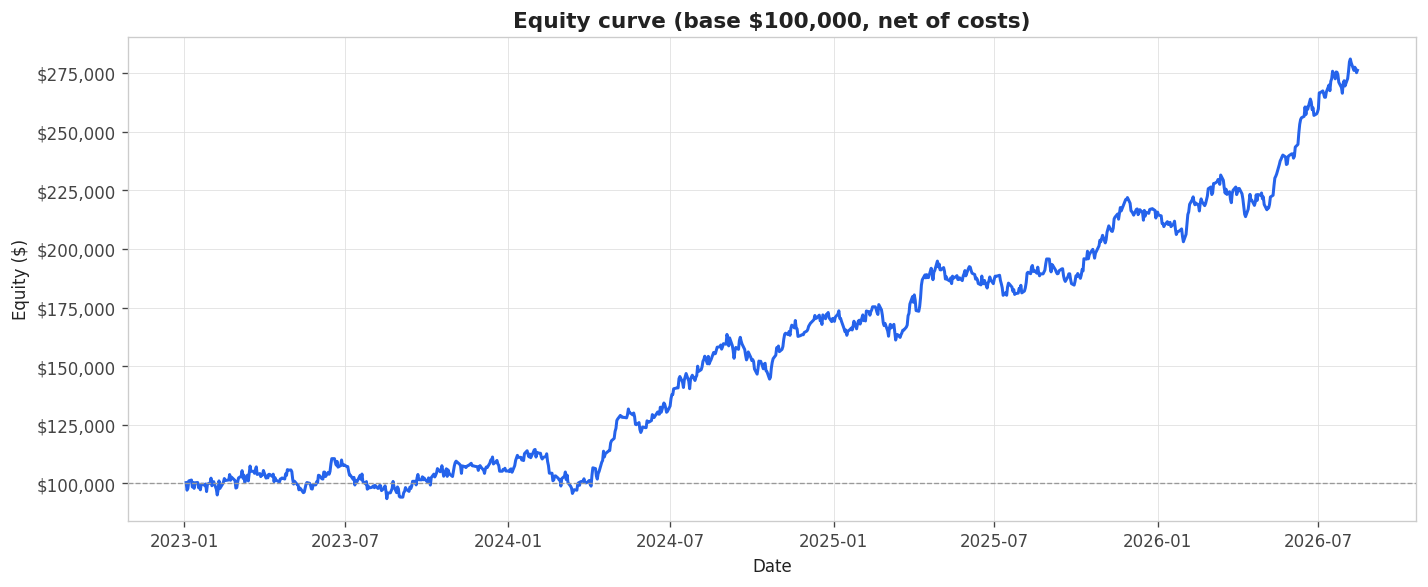

  Total net P&L $176,112   |   max drawdown $19,061   (per backtest contract)


In [ ]:
# =========================================================
# CELL 5b: EQUITY CURVE
# =========================================================
# Cumulative net P&L on a $100,000 base over the simulation window (after
# the OOS filter), on the weekday grid so no-trade stretches show as flat
# lines, not gaps. Per backtest contract, net of costs.

EQUITY_START = 100_000.0

_grid = pd.date_range(df_sim["date"].min(), df_sim["date"].max(), freq="B")
_eq = (df_sim.groupby("date")["profit_net_usd"].sum()
       .reindex(_grid, fill_value=0.0).cumsum() + EQUITY_START)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(_grid, _eq, linewidth=1.8, color="#2563eb")
ax.axhline(EQUITY_START, color="#999999", linewidth=0.8, linestyle="--")
ax.set_title(f"Equity curve (base ${EQUITY_START:,.0f}, net of costs)")
ax.set_xlabel("Date")
ax.set_ylabel("Equity ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
plt.tight_layout()
plt.show()

_tot = _eq.iloc[-1] - EQUITY_START
_mdd = float((_eq.cummax() - _eq).max())
print(f"  Total net P&L ${_tot:,.0f}   |   max drawdown ${_mdd:,.0f}   "
      f"(per backtest contract)")

In [ ]:
# =========================================================
# CELL 6 (v3): APEX 50K EOD CHALLENGE + SIMULATION ENGINE
# =========================================================


from dataclasses import dataclass
import numpy as np


@dataclass
class ApexChallenge:
    name: str
    account_size: float
    profit_target: float
    max_drawdown: float
    eod_trailing: bool
    daily_loss_limit: float = 0
    min_trading_days: int = 0
    max_trading_days: int = MAX_TRADING_DAYS
    dd_lock_profit: float = 100.0   # profit ($) at which the trailing
                                    # threshold stops moving up. PHASE-
                                    # SPECIFIC - see CHALLENGE below.


CHALLENGE = ApexChallenge(
    name="Apex 50K EOD",
    account_size=50_000,
    profit_target=3_000,
    max_drawdown=2_000,          # <- see note 3; 4.0 rules suggest 2_000
    eod_trailing=True,
    daily_loss_limit=1_000.0,    # was never set (defaulted to 0 = off).
                                 # Apex EOD 50K Evaluation DLL = $1,000, fixed (does
                                 # NOT scale during the eval). Source: apextrader
                                 # funding.com/help-center/additional-helpful-items/
                                 # daily-loss-limit-explained/
    max_trading_days=MAX_TRADING_DAYS,
    dd_lock_profit=3_000.0,      # 100.0 is the PERFORMANCE ACCOUNT rule
                                 # and was wrong here. On a Rithmic evaluation the
                                 # EOD threshold stops trailing only once it reaches
                                 # the TARGET balance ($53,000 on a 50K = +3,000
                                 # profit), which is first reached from an EOD high
                                 # above $55,000 -- i.e. never, in an eval that ends
                                 # at +3,000. So the lock is effectively off here,
                                 # which is the correct behaviour. The PA value of
                                 # +100 lives in CELL 11 (PAYOUT_DD_LOCK), where it
                                 # belongs. Rithmic only for now; Tradovate evals
                                 # trail without any lock (set float('inf')).
                                 # Source: apextraderfunding.com/help-center/
                                 # eod-trailing-drawdown-accounts/eod-drawdown-explained/
)

# --- SIZING comes from CELL 2 (NUM_CONTRACTS) — no longer redefined here ---
try:
    NUM_CONTRACTS
except NameError:
    raise RuntimeError("❌ NUM_CONTRACTS not defined — run CELL 2 first.")

_micros = NUM_CONTRACTS * MICRO_PER_MINI
print(f"Challenge : {CHALLENGE.name}")
print(f"Target    : ${CHALLENGE.profit_target:,.0f}")
print(f"Max DD    : ${CHALLENGE.max_drawdown:,.0f} (EOD trailing, "
      f"locks at +${CHALLENGE.dd_lock_profit:,.0f})")
print(f"Deadline  : {EVAL_WINDOW_CALENDAR_DAYS} calendar days"
      f"{'' if EVAL_WINDOW == 'calendar' else f' (modelled as a fixed {MAX_TRADING_DAYS} trading days)'}")
print(f"Instrument: {INSTRUMENT}   (label only - no effect on any calculation)")
print(f"Size      : {NUM_CONTRACTS:g} {MINI_LABEL}"
      f"   (= {_micros:g} {MICRO_LABEL}-equivalents; display only)")
print(f"Backtest  : run at 1 E-mini, so n_contracts=1.0 reproduces it exactly")


# ── Helper functions ─────────────────────────────────────

def wilson_ci(successes, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = (z / denom) * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    return max(0, center - margin), min(1, center + margin)


def verdict_tag(pr):
    """Single source of truth for the verdict scale (Cell 7 + Cell 10)."""
    return ("STRONG" if pr >= .60 else "SOLID" if pr >= .45 else
            "MODERATE" if pr >= .35 else "RISKY" if pr >= .20 else "POOR")


def apply_day_degradation(day_pool, rng, degrade_wr=0.0, degrade_pnl=0.0):
    """Degrade the daily PnL distribution.
    pnl_shrink shrinks WINNING days only (reduces edge, keeps loss/drawdown risk).
    win_rate_adj flips some winning days to SAMPLED losing days. NOTE: this is a
    per-DAY approximation of a per-trade win-rate change (the sim is daily-resolution).
    """
    pool = day_pool.copy()
    if degrade_pnl > 0:
        win_mask = pool["net_pnl_usd"] > 0
        pool.loc[win_mask, "net_pnl_usd"] *= (1.0 - degrade_pnl)
    if degrade_wr < 0:
        win_idx = pool.index[pool["net_pnl_usd"] > 0].to_numpy()
        loss_vals = pool.loc[pool["net_pnl_usd"] < 0, "net_pnl_usd"].to_numpy()
        # base the flip count on actual trade days, not all weekdays
        n_base = int(pool["is_trade_day"].sum()) if "is_trade_day" in pool.columns else len(pool)
        if len(win_idx) > 0:
            n_flip = min(int(round(abs(degrade_wr) * n_base)), len(win_idx))
            if n_flip > 0:
                flip_idx = rng.choice(win_idx, size=n_flip, replace=False)
                if len(loss_vals) > 0:
                    pool.loc[flip_idx, "net_pnl_usd"] = rng.choice(loss_vals, size=n_flip, replace=True)
                else:
                    pool.loc[flip_idx, "net_pnl_usd"] = -abs(pool["net_pnl_usd"].mean())
    return pool


_TRADE_DEG_CACHE = {}


def apply_trade_degradation(bag, degrade_wr=0.0, degrade_pnl=0.0,
                            deg_seed=20240101):
    """Trade-level counterpart to apply_day_degradation, for the engines that
    run off TRADE_BAG.

    pnl_shrink shrinks WINNING trades only. win_rate_adj flips a share of
    winning trades into sampled losing trades; the flipped trade's MAE is
    resampled together with its P&L so the excursion path stays consistent
    with its new outcome. Unlike apply_day_degradation this is a true
    per-trade win-rate change, not a per-day approximation of one.

    Why this exists: CELL 11 and CELL 15 used to switch from TRADE_BAG to the
    day-level pool whenever degradation was requested, which silently swapped
    a DLL-aware trade-resolution engine for a day-resolution one with no DLL.
    Every measured degradation effect then had that engine change baked into
    it. With this helper the engine stays fixed and only the data degrades.

    Returns a bag in the same shape as the input; the input is never mutated.
    Cached because each sweep calls it once per size with identical arguments.
    """
    if degrade_wr == 0.0 and degrade_pnl == 0.0:
        return bag
    key = (id(bag), degrade_wr, degrade_pnl, deg_seed)
    if key in _TRADE_DEG_CACHE:
        return _TRADE_DEG_CACHE[key]

    rng = np.random.default_rng(deg_seed)
    wide = len(bag[0]) == 3                     # (sidx, pnl, mae) vs (pnl, mae)
    lens = [len(d[-2]) for d in bag]
    if sum(lens) == 0:
        return bag
    pnl_old = np.concatenate([np.asarray(d[-2], dtype=float) for d in bag])
    mae_old = np.concatenate([np.asarray(d[-1], dtype=float) for d in bag])
    pnl_new, mae_new = pnl_old.copy(), mae_old.copy()

    if degrade_pnl > 0:
        pnl_new[pnl_new > 0] *= (1.0 - degrade_pnl)

    if degrade_wr < 0:
        win_idx = np.flatnonzero(pnl_new > 0)
        loss_idx = np.flatnonzero(pnl_old < 0)
        n_flip = min(int(round(abs(degrade_wr) * len(pnl_old))), len(win_idx))
        if n_flip > 0 and len(loss_idx) > 0:
            flip = rng.choice(win_idx, size=n_flip, replace=False)
            src = rng.choice(loss_idx, size=n_flip, replace=True)
            pnl_new[flip] = pnl_old[src]
            mae_new[flip] = mae_old[src]

    out, k = [], 0
    for d, n in zip(bag, lens):
        seg_p, seg_m = pnl_new[k:k + n], mae_new[k:k + n]
        out.append((d[0], seg_p, seg_m) if wide else (seg_p, seg_m))
        k += n
    _TRADE_DEG_CACHE[key] = out
    return out

def simulate_apex(daily_pool, challenge, n_sims, n_contracts, rng,
                  degrade_wr=0.0, degrade_pnl=0.0, deg_seed=20240101):
    # degradation uses its OWN generator so `rng` (the sim stream) is
    # untouched -> common-random-numbers preserved across scenarios.
    deg_rng = np.random.default_rng(deg_seed)
    pool = apply_day_degradation(daily_pool, deg_rng, degrade_wr, degrade_pnl)
    pool["scaled_day_pnl"] = pool["net_pnl_usd"] * n_contracts
    vals = pool["scaled_day_pnl"].to_numpy()
    flags = (pool["is_trade_day"].to_numpy()
             if "is_trade_day" in pool.columns else (vals != 0))

    passed = fail_dd = fail_daily = fail_time = 0
    # this daily-resolution engine
    # only has one aggregated net P&L per day (`vals`), no intratrade path/MAE.
    # A day-level "if day_pnl < -DLL: day_pnl = -DLL" cap only clips days that
    # closed net-negative beyond -DLL; it can't catch days that touched -DLL
    # intraday and recovered to close positive, which a real DLL would have
    # liquidated before that recovery happened. That one-sided clip pins the
    # downside at a size-independent constant while the upside keeps scaling
    # with size -- mechanically makes bigger sizes look safer as n_contracts
    # grows, which is backwards and not a real result (confirmed empirically:
    # pass rate rose 53%->71% across sizes with the cap, fell without it).
    # DLL is properly modeled in CELL 6b's trade/excursion engine instead,
    # which has the TRADE_BAG path/MAE data this engine lacks. Left unmodeled
    # here rather than ship the same biased approximation twice.
    dll_hits = 0  # stays 0: DLL not modeled at this resolution, see note above
    days_to_pass, trade_days_to_pass = [], []
    max_dds_all, final_equities, equity_at_pass = [], [], []

    for _ in range(n_sims):
        equity = eod_hwm = sim_max_dd = 0.0
        trade_days = 0
        outcome = None

        _maxd = draw_deadline(rng)
        _days = bootstrap_days(rng, len(vals), _maxd)
        for day in range(1, _maxd + 1):
            idx = _days[day - 1]
            day_pnl = vals[idx]
            equity += day_pnl
            if bool(flags[idx]):
                trade_days += 1

            # EOD trailing drawdown floor, with optional lock
            floor = eod_hwm - challenge.max_drawdown
            if floor > challenge.dd_lock_profit:
                floor = challenge.dd_lock_profit
            current_dd = eod_hwm - equity
            sim_max_dd = max(sim_max_dd, current_dd)

            if equity <= floor:
                outcome = "fail_dd"; break

            if equity > eod_hwm:                      # update EOD HWM after the DD check
                eod_hwm = equity

            # gate on real trading days, not the calendar-day counter
            if equity >= challenge.profit_target and trade_days >= challenge.min_trading_days:
                outcome = "pass"
                days_to_pass.append(day)
                trade_days_to_pass.append(trade_days)
                equity_at_pass.append(equity)
                break

        if outcome is None:
            outcome = "fail_time"
        if outcome == "pass":
            passed += 1
        elif outcome == "fail_dd":
            fail_dd += 1
        # NOTE: "fail_daily" outcome removed (see DLL note above) -- a DLL hit
        # never fails the sim at this resolution, so this branch is now
        # unreachable; fail_daily is kept at 0 below only so downstream
        # cells reading res["fail_daily"] don't need to change.
        else:
            fail_time += 1
        max_dds_all.append(sim_max_dd)
        final_equities.append(equity)

    pr = passed / n_sims
    return {
        "challenge_name": challenge.name, "n_sims": n_sims,
        "passed": passed, "fail_dd": fail_dd, "fail_daily": fail_daily, "fail_time": fail_time,
        "dll_hits": dll_hits,
            "dll_hit_rate": dll_hits / max(1, n_sims * DEADLINE_POOL.mean()),
        "pass_rate": pr, "pass_rate_ci": wilson_ci(passed, n_sims),
        "avg_days_to_pass": np.mean(days_to_pass) if days_to_pass else None,
        "median_days_to_pass": np.median(days_to_pass) if days_to_pass else None,
        "avg_trade_days_to_pass": np.mean(trade_days_to_pass) if trade_days_to_pass else None,
        "days_to_pass": np.array(days_to_pass),
        "avg_max_dd": np.mean(max_dds_all), "p50_max_dd": np.median(max_dds_all),
        "p90_max_dd": np.percentile(max_dds_all, 90),
        "p95_max_dd": np.percentile(max_dds_all, 95),
        "worst_max_dd": np.max(max_dds_all),
        "avg_final_equity": np.mean(final_equities),
        "avg_equity_at_pass": np.mean(equity_at_pass) if equity_at_pass else None,
        "max_dds_all": np.array(max_dds_all),
        "final_equities": np.array(final_equities),
    }


def simulate_paths(daily_pool, challenge, n_paths, n_contracts, rng):
    """
    Equity paths for the spaghetti chart. Uses the same DD logic (incl. lock).
    Failed paths STOP at their failure day (NaN after). Passed paths flatline.
    """
    pool = daily_pool.copy()
    pool["scaled_day_pnl"] = pool["net_pnl_usd"] * n_contracts
    vals = pool["scaled_day_pnl"].to_numpy()

    paths = np.full((n_paths, challenge.max_trading_days), np.nan)
    outcomes = []

    for i in range(n_paths):
        equity = eod_hwm = 0.0
        outcome = None

        _maxd = draw_deadline(rng)
        _days = bootstrap_days(rng, len(vals), _maxd)
        for d in range(_maxd):
            equity += vals[_days[d]]
            paths[i, d] = equity

            floor = eod_hwm - challenge.max_drawdown
            if floor > challenge.dd_lock_profit:
                floor = challenge.dd_lock_profit

            if equity <= floor:
                outcome = "fail_dd"
                break

            if equity > eod_hwm:
                eod_hwm = equity

            if equity >= challenge.profit_target:
                outcome = "pass"
                paths[i, d+1:] = equity
                break

        if outcome is None:
            outcome = "fail_time"

        outcomes.append(outcome)

    return {"paths": paths, "outcomes": np.array(outcomes)}


def print_results(r, ch):
    ci = r["pass_rate_ci"]
    print(f"\n{'='*55}")
    print(f"  {r['challenge_name']}")
    print(f"{'='*55}")
    print(f"  Target: ${ch.profit_target:,.0f}  |  Max DD: ${ch.max_drawdown:,.0f} (EOD trailing)")
    print(f"  Deadline: {EVAL_WINDOW_CALENDAR_DAYS} calendar days  |  "
          f"Sims: {r['n_sims']:,}")
    print(f"\n  >>> PASS RATE: {r['pass_rate']:.1%}  [95% CI: {ci[0]:.1%} - {ci[1]:.1%}] <<<")
    print(f"\n  OUTCOMES:")
    print(f"    Passed     : {r['passed']:>6,}  ({r['passed']/r['n_sims']:.1%})")
    print(f"    Fail DD    : {r['fail_dd']:>6,}  ({r['fail_dd']/r['n_sims']:.1%})")
    print(f"    Fail Daily : {r['fail_daily']:>6,}  ({r['fail_daily']/r['n_sims']:.1%})")
    print(f"    Fail Time  : {r['fail_time']:>6,}  ({r['fail_time']/r['n_sims']:.1%})")
    if r["avg_days_to_pass"] is not None:
        print(f"\n  TIMING:")
        print(f"    Avg days to pass : {r['avg_days_to_pass']:.1f}  (calendar weekdays)")
        print(f"    Median           : {r['median_days_to_pass']:.1f}")
        if r.get("avg_trade_days_to_pass") is not None:
            print(f"    Avg TRADING days : {r['avg_trade_days_to_pass']:.1f}")
    print(f"\n  DRAWDOWN:")
    print(f"    Avg Max DD  : ${r['avg_max_dd']:>8,.0f}")
    print(f"    P90 Max DD  : ${r['p90_max_dd']:>8,.0f}")
    print(f"    P95 Max DD  : ${r['p95_max_dd']:>8,.0f}")
    print(f"    Worst DD    : ${r['worst_max_dd']:>8,.0f}")

    print(f"\n  VERDICT: {verdict_tag(r['pass_rate'])}")


print("Simulation engine loaded: simulate_apex, simulate_paths, print_results, verdict_tag")

Challenge : Apex 50K EOD
Target    : $3,000
Max DD    : $2,000 (EOD trailing, locks at +$3,000)
Deadline  : 30 calendar days
Instrument: NQ   (label only - no effect on any calculation)
Size      : 1 MINI   (= 10 MICRO-equivalents; display only)
Backtest  : run at 1 E-mini, so n_contracts=1.0 reproduces it exactly
Simulation engine loaded: simulate_apex, simulate_paths, print_results, verdict_tag


In [ ]:
# =========================================================
# CELL 6b: ENGINE CHOICE - DAILY / TRADE / EXCURSION
# =========================================================
# ENGINE = "excursion": trade level AND the path INSIDE each trade - the
# floor is checked at each trade's worst point (its MAE) before its
# close. This is how the firm's risk engine sees your account, and
# it uses every trade's measured excursion (Cell 4b), not outliers.
# Requires Cell 4b. The most honest engine at every size.
# ENGINE = "trade": floor checked at trade CLOSES only. Honest about loss
# sequencing, blind inside trades - optimistic at large sizes.
# ENGINE = "daily": the original Cell 6 day-level engine - optimistic at
# large sizes (intraday losses net away before the EOD check).
# Conservatism notes (excursion): the MAE is applied BEFORE the close (worst
# first), and the TARGET is only checked at closes (run-up is not used to
# pass early). Both choices lean pessimistic, which is the right direction.
# Run order: 6 -> 4b -> 6b -> 7-10.

ENGINE = "excursion"

_bag_src = df_sim.sort_values("datetime")
_bag_days = pd.date_range(_bag_src["date"].min(), _bag_src["date"].max(), freq="B")
_mae_col = ("mae_usd" if ("mae_usd" in _bag_src.columns) else None)
TRADE_BAG = []
for _d in _bag_days:
    _t = _bag_src[_bag_src["date"] == _d]
    _pnl = _t["profit_net_usd"].to_numpy()
    _mae = (_t[_mae_col].to_numpy() if _mae_col is not None
            else np.clip(-_pnl, 0, None))
    TRADE_BAG.append((_pnl, _mae))

if ENGINE == "excursion" and (_mae_col is None or not globals().get("HAS_EXCURSIONS", False)):
    print("⚠️  Excursion data missing (run Cell 4b) - falling back to ENGINE='trade'.")
    ENGINE = "trade"

# capture Cell 6's engine ONCE (guard: never overwrite it with one of ours
# if this cell is re-run after the switch)
if simulate_apex.__name__ == "simulate_apex":
    simulate_apex_daily = simulate_apex

def _apex_trade_engine(challenge, n_sims, n_contracts, rng, use_mae):
    passed = fail_dd = fail_time = 0
    dll_hits = 0   # days where the Daily Loss Limit forced a
                   # liquidation (informational -- does not fail the eval)
    days_to_pass, tdays_to_pass, max_dds = [], [], []
    for _ in range(n_sims):
        eq = hwm = mdd = 0.0
        td = 0
        out = None
        _maxd = draw_deadline(rng)
        _days = bootstrap_days(rng, len(TRADE_BAG), _maxd)
        for day in range(1, _maxd + 1):
            pnl, mae = TRADE_BAG[_days[day - 1]]
            if len(pnl):
                td += 1
            floor = hwm - challenge.max_drawdown       # EOD-trailing floor,
            if floor > challenge.dd_lock_profit:       # frozen within the day
                floor = challenge.dd_lock_profit
            # Daily Loss Limit, measured from today's open equity. A
            # breach liquidates the day's position and pauses trading for the
            # REST OF THIS DAY ONLY -- it does not fail the evaluation (Apex:
            # "Does hitting DLL fail my account? No."). At trade resolution we
            # can model this exactly: once the running equity (or, with MAE,
            # the intratrade trough) touches the DLL floor, stop processing
            # further trades this day and carry eq forward at that floor.
            day_open_eq = eq
            dll_floor = (day_open_eq - challenge.daily_loss_limit
                         if challenge.daily_loss_limit > 0 else -np.inf)
            # the DLL floor and the EOD floor are BOTH enforced in
            # real time, so whichever sits HIGHER is touched first on the way
            # down and is the one that decides the outcome. On any day opening
            # less than the DLL below the EOD high -- the normal case -- the
            # DLL floor is the higher one: Apex liquidates there and pauses the
            # session, and the EOD floor is then unreachable for the rest of
            # that day. Checking the EOD floor first (the old order) reported
            # failures that cannot happen. Ties (dll_floor == floor, which is
            # exactly the state after one DLL day) resolve to the EOD floor,
            # i.e. to a fail -- the conservative reading.
            dll_first = dll_floor > floor
            for j in range(len(pnl)):
                if use_mae:                            # worst point INSIDE the trade
                    trough = eq - mae[j] * n_contracts
                    mdd = max(mdd, hwm - trough)
                    if dll_first:
                        if trough <= dll_floor:
                            eq = dll_floor
                            dll_hits += 1
                            break
                    elif trough <= floor:
                        out = "dd"
                        break
                eq += pnl[j] * n_contracts
                mdd = max(mdd, hwm - eq)
                if dll_first:
                    if eq <= dll_floor:
                        eq = dll_floor
                        dll_hits += 1
                        break
                elif eq <= floor:                      # checked at the close too
                    out = "dd"
                    break
                if (eq >= challenge.profit_target and
                        td >= challenge.min_trading_days):
                    out = "pass"
                    days_to_pass.append(day)
                    tdays_to_pass.append(td)
                    break
            if out:
                break
            if eq > hwm:                               # floor ratchets at EOD
                hwm = eq
        if out is None:
            out = "time"
        passed += out == "pass"; fail_dd += out == "dd"; fail_time += out == "time"
        max_dds.append(mdd)
    _dds = np.array(max_dds)
    return {"challenge_name": challenge.name,
            "n_contracts": n_contracts,
            "micros": int(round(n_contracts * MICRO_PER_MINI)),
            "pass_rate": passed / n_sims,
            "pass_rate_ci": wilson_ci(passed, n_sims),
            "passed": passed, "fail_dd": fail_dd, "fail_daily": 0,
            "dll_hits": dll_hits,
            "dll_hit_rate": dll_hits / max(1, n_sims * DEADLINE_POOL.mean()),
            "fail_time": fail_time, "n_sims": n_sims,
            "avg_days_to_pass": float(np.mean(days_to_pass)) if days_to_pass else None,
            "median_days_to_pass": float(np.median(days_to_pass)) if days_to_pass else float("nan"),
            "p90_days_to_pass": float(np.percentile(days_to_pass, 90)) if days_to_pass else float("nan"),
            "avg_trade_days_to_pass": float(np.mean(tdays_to_pass)) if tdays_to_pass else None,
            "days_to_pass": np.array(days_to_pass),
            "max_dds": _dds,
            "avg_max_dd": float(_dds.mean()),
            "p50_max_dd": float(np.median(_dds)),
            "p90_max_dd": float(np.percentile(_dds, 90)),
            "p95_max_dd": float(np.percentile(_dds, 95)),
            "worst_max_dd": float(_dds.max())}

def simulate_apex_trade(daily_pool, challenge, n_sims, n_contracts, rng, **kw):
    return _apex_trade_engine(challenge, n_sims, n_contracts, rng, use_mae=False)

def simulate_apex_excursion(daily_pool, challenge, n_sims, n_contracts, rng, **kw):
    return _apex_trade_engine(challenge, n_sims, n_contracts, rng, use_mae=True)

simulate_apex = {"daily": simulate_apex_daily,
                 "trade": simulate_apex_trade,
                 "excursion": simulate_apex_excursion}[ENGINE]

# The funded engines (CELL 11 / CELL 15) used the MAE unconditionally, so with
# ENGINE="trade" or "daily" the eval phase was checked at closes while the funded
# phase was still checked inside trades -- two different models in one report.
USE_MAE = (ENGINE == "excursion")


def bootstrap_days(rng, n_bag, n_days):
    """Day indices for one simulated run, drawn from the history.

    BOOTSTRAP_BLOCK == 1 is the plain iid bootstrap. Above that it is a
    moving-block bootstrap: a random start, then consecutive days, wrapping at
    the end of the sample. Blocks keep runs of good and bad days together,
    which is what a trailing drawdown actually reacts to.
    """
    b = max(1, int(globals().get("BOOTSTRAP_BLOCK", 1)))
    if b == 1:
        return rng.integers(n_bag, size=n_days)
    starts = rng.integers(n_bag, size=-(-n_days // b))
    return ((starts[:, None] + np.arange(b)) % n_bag).ravel()[:n_days]


TRADE_BAG_FULL = TRADE_BAG
_SPLIT_I = int(round(len(TRADE_BAG_FULL) * (1.0 - float(VALIDATION_SPLIT))))
_SAMPLE_SLICE = slice(None)
SAMPLE_NAME = "full sample"


def set_sample(which):
    """Point TRADE_BAG and daily_pool at 'train', 'validation' or 'full'.

    Selection (size, and the mix in MultiStrats) runs on 'train'; the reported
    result runs on 'validation', which the selection never saw. With
    VALIDATION_SPLIT = 0 all three are the same data and the notebook says so.
    """
    global TRADE_BAG, daily_pool, _SAMPLE_SLICE, SAMPLE_NAME
    if VALIDATION_SPLIT <= 0:
        _SAMPLE_SLICE, SAMPLE_NAME = slice(None), "full sample (no holdout)"
    elif which == "train":
        _SAMPLE_SLICE, SAMPLE_NAME = slice(0, _SPLIT_I), "train"
    elif which == "validation":
        _SAMPLE_SLICE, SAMPLE_NAME = slice(_SPLIT_I, None), "validation (held out)"
    else:
        _SAMPLE_SLICE, SAMPLE_NAME = slice(None), "full sample"
    TRADE_BAG = TRADE_BAG_FULL[_SAMPLE_SLICE]
    _dp = globals().get("DAILY_POOL_FULL", None)
    if _dp is not None:
        _at = dict(getattr(_dp, "attrs", {}))
        daily_pool = _dp.iloc[_SAMPLE_SLICE].copy()
        daily_pool.attrs.update(_at)
    return SAMPLE_NAME


if VALIDATION_SPLIT > 0:
    _d0 = _bag_days[0].date(); _d1 = _bag_days[_SPLIT_I - 1].date()
    _d2 = _bag_days[_SPLIT_I].date(); _d3 = _bag_days[-1].date()
    print(f"   Holdout: selection on {_d0} to {_d1} ({_SPLIT_I} weekdays), "
          f"reported on {_d2} to {_d3} "
          f"({len(TRADE_BAG_FULL) - _SPLIT_I} weekdays).")
else:
    print("   Holdout: DISABLED (VALIDATION_SPLIT = 0) - every number below is "
          "in-sample and flatters whatever this notebook selects.")



# ── Evaluation deadline: 30 calendar days, in trading days ───────────────
# For every possible purchase date in the sample, count the trading days that
# fall inside the following EVAL_WINDOW_CALENDAR_DAYS. Drawing from that gives
# each simulated evaluation a deadline with the right length, instead of one
# rounded average applied to all of them.
_cal_all = pd.date_range(_bag_days[0], _bag_days[-1], freq="D")
_bag_ix = pd.DatetimeIndex(_bag_days)
_start = _bag_ix.searchsorted(_cal_all, side="left")
_stop = _bag_ix.searchsorted(
    _cal_all + pd.Timedelta(days=EVAL_WINDOW_CALENDAR_DAYS - 1), side="right")
# Only purchase dates whose whole window fits inside the sample. Without this,
# start dates near the end of the data produce truncated windows (1..19 days)
# that are an artefact of where the file stops, not a rule.
_fits = (_cal_all + pd.Timedelta(days=EVAL_WINDOW_CALENDAR_DAYS - 1)) <= _bag_days[-1]
DEADLINE_POOL = (_stop - _start)[_fits]
DEADLINE_POOL = DEADLINE_POOL[DEADLINE_POOL > 0]
if EVAL_WINDOW != "calendar" or len(DEADLINE_POOL) == 0:
    DEADLINE_POOL = np.array([MAX_TRADING_DAYS])
DEADLINE_MAX = int(DEADLINE_POOL.max())
CHALLENGE.max_trading_days = DEADLINE_MAX      # array sizing and axis limits


def draw_deadline(rng):
    """Trading days available to one simulated evaluation."""
    return int(DEADLINE_POOL[rng.integers(len(DEADLINE_POOL))])


if EVAL_WINDOW == "calendar":
    _u, _c = np.unique(DEADLINE_POOL, return_counts=True)
    print(f"   Deadline: {EVAL_WINDOW_CALENDAR_DAYS} calendar days = "
          + ", ".join(f"{d} trading days {n/len(DEADLINE_POOL):.0%}"
                      for d, n in zip(_u, _c))
          + f"  (mean {DEADLINE_POOL.mean():.2f})")
else:
    print(f"   Deadline: fixed {MAX_TRADING_DAYS} trading days "
          f"(EVAL_WINDOW = 'fixed').")

print(f"✅ ENGINE = {ENGINE!r} - Cells 7-10 will use it on re-run.")
print(f"   Funded engines (CELL 11/15) follow the same mode: use_mae={USE_MAE}.")
_COV = globals().get("EXCURSION_COVERAGE", None)
if USE_MAE and _COV is not None and _COV < 1.0:
    print(f"   Excursion coverage: {_COV:.1%} measured, {1-_COV:.1%} synthetic "
          f"(MAE = realised loss, i.e. 0 for winners -> optimistic).")
    # Sensitivity: the same data through both models bounds how far the missing
    # excursions can move the answer. If the two are close, the gap does not
    # matter; if they are far apart, no number here is better than its coverage.
    _s_a = _apex_trade_engine(CHALLENGE, 2000, NUM_CONTRACTS,
                       np.random.default_rng(SEED + 9100), True)["pass_rate"]
    _s_b = _apex_trade_engine(CHALLENGE, 2000, NUM_CONTRACTS,
                       np.random.default_rng(SEED + 9100), False)["pass_rate"]
    print(f"   Sensitivity at {NUM_CONTRACTS:g}: pass rate {_s_a:.1%} (excursion) "
          f"vs {_s_b:.1%} (close-only). Every number in this report inherits that "
          f"spread in proportion to the {1-_COV:.1%} synthetic share.")
print(f"   Trade bag: {len(TRADE_BAG)} weekdays, "
      f"{sum(len(p) for p, m in TRADE_BAG)} trades in original intraday order.")
if ENGINE == "excursion":
    _all_mae = np.concatenate([m for p, m in TRADE_BAG if len(m)])
    _p95_mae = float(np.percentile(_all_mae, 95))
    if _p95_mae > 0:
        print(f"   Path bound (measured on {len(_all_mae)} trades): a typical bad "
              f"excursion (P95 MAE ${_p95_mae:,.0f}/contract) fills the "
              f"${CHALLENGE.max_drawdown:,.0f} room at "
              f"{CHALLENGE.max_drawdown / _p95_mae:.1f} contracts from a fresh start.")

   Holdout: selection on 2023-01-03 to 2025-07-15 (661 weekdays), reported on 2025-07-16 to 2026-08-14 (283 weekdays).
   Deadline: 30 calendar days = 20 trading days 14%, 21 trading days 29%, 22 trading days 57%  (mean 21.43)
✅ ENGINE = 'excursion' - Cells 7-10 will use it on re-run.
   Funded engines (CELL 11/15) follow the same mode: use_mae=True.
   Trade bag: 944 weekdays, 2646 trades in original intraday order.
   Path bound (measured on 2646 trades): a typical bad excursion (P95 MAE $1,610/contract) fills the $2,000 room at 1.2 contracts from a fresh start.


In [ ]:
# =========================================================
# CELL 7: RUN MAIN SIMULATION
# =========================================================

daily_pool = daily_full[["date", "n_trades", "net_pnl_usd", "is_trade_day"]].copy()
DAILY_POOL_FULL = daily_pool          # set_sample() slices this one
set_sample("full")

res = simulate_apex(
    daily_pool=daily_pool,
    challenge=CHALLENGE,
    n_sims=PROP_MC_SIMS,
    n_contracts=NUM_CONTRACTS,
    rng=np.random.default_rng(SEED),
)
print(f"Sample : {'OOS from ' + str(pd.to_datetime(OOS_START_DATE).date()) if OOS_START_DATE else 'FULL sample (in-sample if raw backtest)'}"
      f"  |  {len(df_sim)} trades over {len(daily_full)} weekdays")
print(f"Sizing : {NUM_CONTRACTS:g} MINI-equivalent contract(s)")
print_results(res, CHALLENGE)


Sample : OOS from 2023-01-01  |  2646 trades over 944 weekdays
Sizing : 1 MINI-equivalent contract(s)

  Apex 50K EOD
  Target: $3,000  |  Max DD: $2,000 (EOD trailing)
  Deadline: 30 calendar days  |  Sims: 20,000

  >>> PASS RATE: 38.2%  [95% CI: 37.5% - 38.9%] <<<

  OUTCOMES:
    Passed     :  7,636  (38.2%)
    Fail DD    : 12,364  (61.8%)
    Fail Daily :      0  (0.0%)
    Fail Time  :      0  (0.0%)

  TIMING:
    Avg days to pass : 2.9  (calendar weekdays)
    Median           : 3.0
    Avg TRADING days : 2.8

  DRAWDOWN:
    Avg Max DD  : $   1,999
    P90 Max DD  : $   2,740
    P95 Max DD  : $   3,217
    Worst DD    : $   4,847

  VERDICT: MODERATE


In [ ]:
# =========================================================
# CELL 8: POSITION SIZE SWEEP
# =========================================================

_sample_tag = (f"OOS from {pd.to_datetime(OOS_START_DATE).date()}"
               if OOS_START_DATE else "FULL sample")

print("\n" + "═" * 60)
print(f"  MICRO SIZE SWEEP — {CHALLENGE.name}  ({_sample_tag})")
print("═" * 60)
print(f"  {'MICRO':>6} {'Pass%':>8} {'95% CI':>17} {'AvgDD':>10} {'P95DD':>10} {'AvgDays':>8}")
print("  " + "─" * 66)

set_sample("train")        # the size is SELECTED here, so it is selected on train
sweep_data = []
for nc in SWEEP_CONTRACTS:
    rs = simulate_apex(
        daily_pool=daily_pool, challenge=CHALLENGE,
        n_sims=PROP_MC_SIMS, n_contracts=nc,
        rng=np.random.default_rng(SEED + 2000),
    )
    ci = rs["pass_rate_ci"]
    ad = rs["avg_days_to_pass"] if rs["avg_days_to_pass"] is not None else np.nan
    micros = int(round(nc * MICRO_PER_MINI))
    print(f"  {micros:>5}x {rs['pass_rate']:>7.1%}   [{ci[0]:>5.1%} - {ci[1]:>5.1%}]  "
          f"${rs['avg_max_dd']:>8,.0f}  ${rs['p95_max_dd']:>8,.0f}  {ad:>7.1f}")
    sweep_data.append({"nc": nc, "micros": micros, "pr": rs["pass_rate"], "ci": ci,
                       "dd": rs["avg_max_dd"], "p95dd": rs["p95_max_dd"], "days": ad})

_sorted = sorted(sweep_data, key=lambda s: s["pr"], reverse=True)
_best = _sorted[0]
_tied = [s for s in _sorted[1:] if s["ci"][1] >= _best["ci"][0]]

if _tied:
    _rng_lo = min([_best] + _tied, key=lambda s: s["micros"])["micros"]
    _rng_hi = max([_best] + _tied, key=lambda s: s["micros"])["micros"]
    print(f"\n  >>> BEST: {_best['micros']} MICRO at {_best['pr']:.1%}, but statistically "
          f"tied with {len(_tied)} other size(s) ({_rng_lo}-{_rng_hi} MICRO range) <<<")
    print(f"      Within a tie, prefer the SMALLER size: same pass odds, "
          f"less drawdown risk (P95 DD column).")
else:
    print(f"\n  >>> BEST: {_best['micros']} MICRO → {_best['pr']:.1%} <<<")

# ── The selected size, measured on data the selection never saw ──────────
set_sample("validation")
_val = simulate_apex(daily_pool=daily_pool, challenge=CHALLENGE,
                     n_sims=PROP_MC_SIMS, n_contracts=_best["nc"],
                     rng=np.random.default_rng(SEED + 2600))
_gap = _best["pr"] - _val["pass_rate"]
print(f"\n  HOLDOUT CHECK ({SAMPLE_NAME}, {len(TRADE_BAG)} weekdays)")
print(f"    {_best['micros']} MICRO: {_best['pr']:.1%} on train -> "
      f"{_val['pass_rate']:.1%} held out   ({-_gap:+.1%})")
if VALIDATION_SPLIT <= 0:
    print(f"    No holdout configured - this is the same number twice.")
elif _gap > 0.10:
    print(f"    The size that won on train gives back {_gap:.0%} out of sample. "
          f"Treat the sweep as a rough guide, not a ranking.")
elif _gap > 0.05:
    print(f"    Moderate give-back. Expect the live number nearer the holdout one.")
else:
    print(f"    Holds up out of sample.")
print(f"    Sizes are compared on train; every number from CELL 9 onward is "
      f"computed on the holdout.")

# Cells 9-16 run on the holdout: they report, they no longer select.


════════════════════════════════════════════════════════════
  MICRO SIZE SWEEP — Apex 50K EOD  (OOS from 2023-01-01)
════════════════════════════════════════════════════════════
   MICRO    Pass%            95% CI      AvgDD      P95DD  AvgDays
  ──────────────────────────────────────────────────────────────────
      3x   28.8%   [28.2% - 29.5%]  $   1,777  $   2,386     12.4
      5x   34.7%   [34.0% - 35.3%]  $   1,922  $   2,638      7.0
      7x   36.7%   [36.0% - 37.3%]  $   1,846  $   2,748      4.6
     10x   37.2%   [36.6% - 37.9%]  $   2,028  $   3,234      3.0
     11x   38.1%   [37.5% - 38.8%]  $   2,084  $   3,424      2.7
     13x   39.9%   [39.3% - 40.6%]  $   2,146  $   3,226      2.2
     15x   37.9%   [37.2% - 38.5%]  $   2,358  $   3,463      2.1
     17x   38.0%   [37.3% - 38.6%]  $   2,461  $   3,737      1.8
     20x   37.4%   [36.7% - 38.0%]  $   2,692  $   4,220      1.6

  >>> BEST: 13 MICRO → 39.9% <<<

  HOLDOUT CHECK (validation (held out), 283 weekdays)
 

In [ ]:
# =========================================================
# CELL 8b: STAGED SIZING TEST - SMALL UNTIL A BUFFER, THEN OPTIMAL
# =========================================================
# Tests: trade a REDUCED size until the account has built a profit buffer,
# then switch to the optimal size. Uses the SAME engine selected in Cell 6b
# (trade-level, with the MAE excursion check when ENGINE="excursion"), so
# the flat baseline here is consistent with the Cell 8 sweep.
# STAGED_MODE: "dynamic" = size follows equity (drops back below the buffer);
# "ratchet" = once up, stay at optimal size for good.
# Requires Cells 6b (TRADE_BAG) and 8 (_best).

BUFFER_LEVEL = 1_000.0
STAGE1_FRACS = [0.25, 0.50, 0.75]
STAGED_MODE  = "dynamic"
STAGED_SIMS  = PROP_MC_SIMS
_USE_MAE     = (ENGINE == "excursion")

_opt_nc = _best["nc"]

def simulate_staged(challenge, n_sims, nc_small, nc_big, buffer_usd, rng,
                    mode="dynamic", use_mae=_USE_MAE):
    passed = 0
    for _ in range(n_sims):
        eq = hwm = 0.0
        td = 0
        big = False
        out = None
        _maxd = draw_deadline(rng)
        _days = bootstrap_days(rng, len(TRADE_BAG), _maxd)
        for day in range(1, _maxd + 1):
            pnl, mae = TRADE_BAG[_days[day - 1]]
            if len(pnl):
                td += 1
            floor = hwm - challenge.max_drawdown
            if floor > challenge.dd_lock_profit:
                floor = challenge.dd_lock_profit
            for j in range(len(pnl)):
                # size decided at THIS trade's entry, from current equity
                if mode == "ratchet":
                    big = big or (eq >= buffer_usd)
                else:
                    big = eq >= buffer_usd
                sz = nc_big if big else nc_small
                if use_mae:
                    if eq - mae[j] * sz <= floor:      # worst point inside trade
                        out = "dd"
                        break
                eq += pnl[j] * sz
                if eq <= floor:
                    out = "dd"
                    break
                if (eq >= challenge.profit_target and
                        td >= challenge.min_trading_days):
                    out = "pass"
                    break
            if out:
                break
            if eq > hwm:
                hwm = eq
        passed += out == "pass"
    return passed / n_sims

_p_flat = simulate_staged(CHALLENGE, STAGED_SIMS, _opt_nc, _opt_nc,
                          BUFFER_LEVEL, np.random.default_rng(SEED + 15000),
                          STAGED_MODE)
_lo_f, _hi_f = wilson_ci(int(round(_p_flat * STAGED_SIMS)), STAGED_SIMS)

print("═" * 74)
print(f"  STAGED SIZING - small until +${BUFFER_LEVEL:,.0f}, then {_opt_nc:g}x "
      f"({STAGED_MODE} mode, ENGINE={ENGINE!r}, {STAGED_SIMS:,} sims)")
print("═" * 74)
print(f"  {'Stage 1 size':>14} {'Pass%':>8} {'95% CI':>17} {'vs flat':>9}")
print("  " + "─" * 54)
print(f"  {'flat ' + format(_opt_nc, 'g') + 'x':>14} {_p_flat:>8.1%}   "
      f"[{_lo_f:>5.1%} - {_hi_f:>5.1%}]  baseline")

_rows = []
for fr in STAGE1_FRACS:
    nc1 = round(fr * _opt_nc, 2)
    p = simulate_staged(CHALLENGE, STAGED_SIMS, nc1, _opt_nc,
                        BUFFER_LEVEL, np.random.default_rng(SEED + 15000),
                        STAGED_MODE)
    lo, hi = wilson_ci(int(round(p * STAGED_SIMS)), STAGED_SIMS)
    _rows.append((nc1, p, lo, hi))
    print(f"  {format(nc1, 'g') + 'x->' + format(_opt_nc, 'g') + 'x':>14} "
          f"{p:>8.1%}   [{lo:>5.1%} - {hi:>5.1%}]  {(p - _p_flat) * 100:>+8.1f}pp")

_best_staged = max(_rows, key=lambda r: r[1])
if _best_staged[2] > _hi_f:
    print(f"\n  >>> Staging HELPS here: {_best_staged[0]:g}x until the buffer beats "
          f"flat sizing outside the CIs "
          f"({_best_staged[1]:.1%} vs {_p_flat:.1%}). <<<")
elif _best_staged[3] < _lo_f:
    print(f"\n  >>> Staging HURTS here: every stage-1 size lowers the pass rate "
          f"outside the CIs. Under this deadline, the time spent trading small "
          f"costs more than the early protection is worth. <<<")
else:
    print(f"\n  >>> No significant difference: the best staged variant "
          f"({_best_staged[1]:.1%}) is statistically tied with flat sizing "
          f"({_p_flat:.1%}). The buffer idea neither helps nor hurts the EVAL -")
    print(f"      its real value, if any, is psychological, and on a funded "
          f"account (no deadline) the same test can come out differently. <<<")
print(f"\n  Consistency check: the flat baseline above should sit within CI of the")
print(f"  Cell 8 row for the same size (different seed stream, same engine).")

══════════════════════════════════════════════════════════════════════════
  STAGED SIZING - small until +$1,000, then 1.3x (dynamic mode, ENGINE='excursion', 20,000 sims)
══════════════════════════════════════════════════════════════════════════
    Stage 1 size    Pass%            95% CI   vs flat
  ──────────────────────────────────────────────────────
       flat 1.3x    41.8%   [41.2% - 42.5%]  baseline
     0.33x->1.3x    42.4%   [41.7% - 43.1%]      +0.5pp
     0.65x->1.3x    41.7%   [41.0% - 42.4%]      -0.1pp
     0.98x->1.3x    42.5%   [41.9% - 43.2%]      +0.7pp

  >>> No significant difference: the best staged variant (42.5%) is statistically tied with flat sizing (41.8%). The buffer idea neither helps nor hurts the EVAL -
      its real value, if any, is psychological, and on a funded account (no deadline) the same test can come out differently. <<<

  Consistency check: the flat baseline above should sit within CI of the
  Cell 8 row for the same size (different seed stre

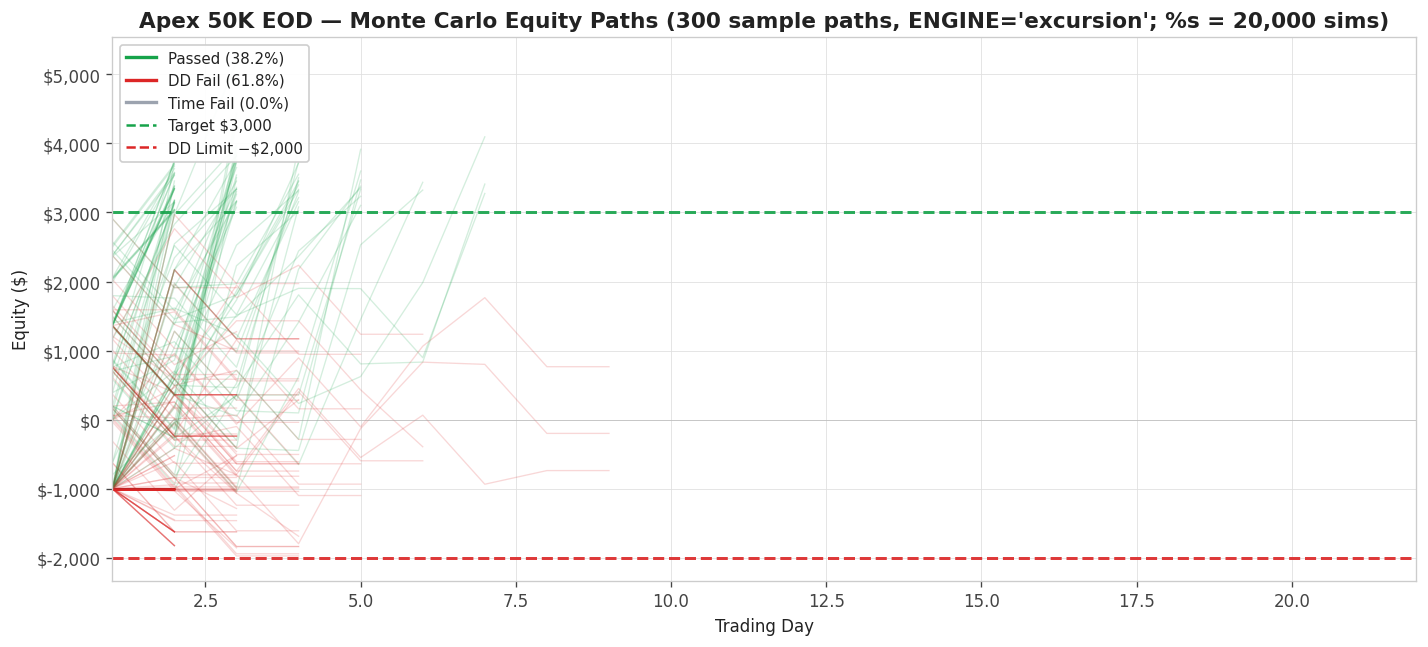

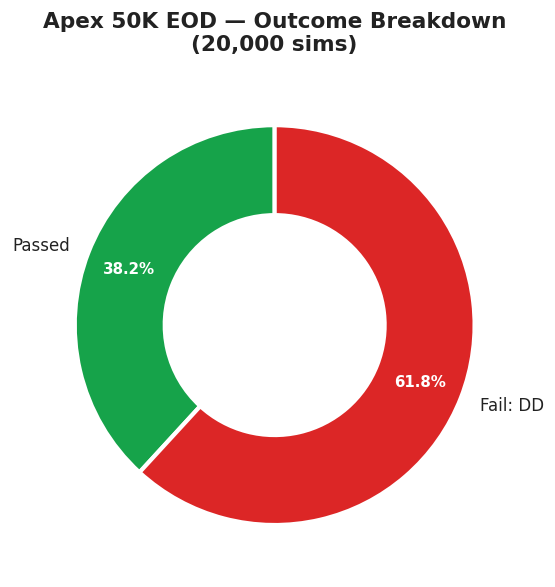

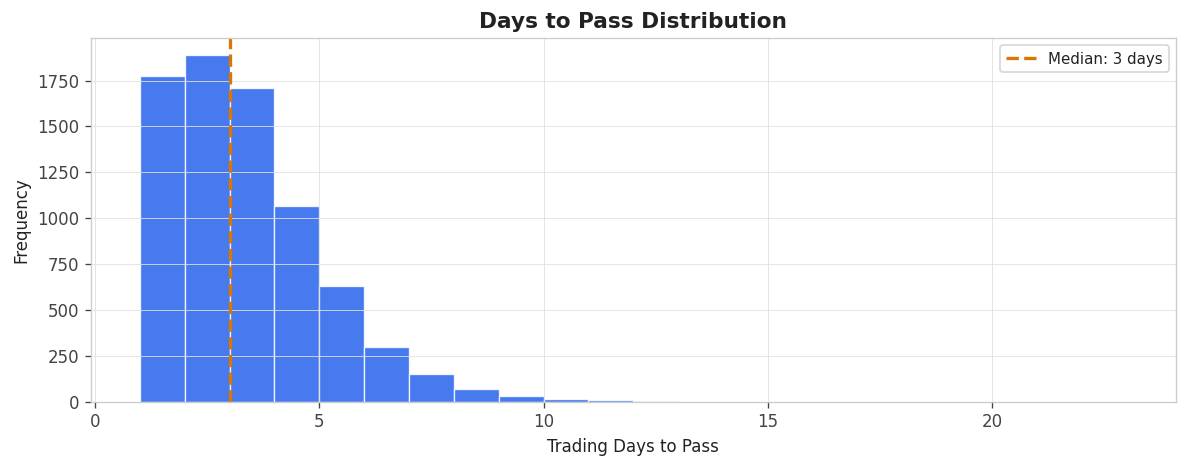

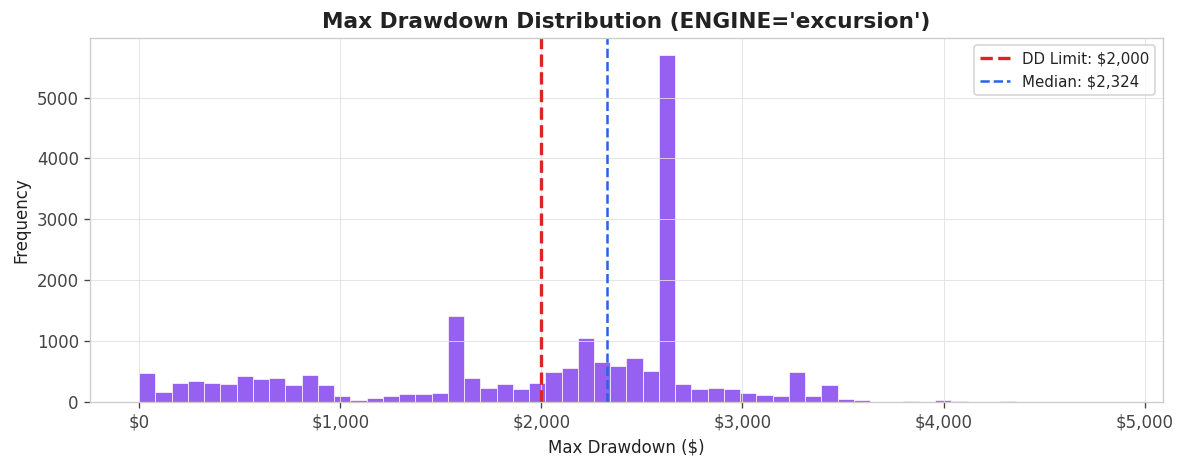

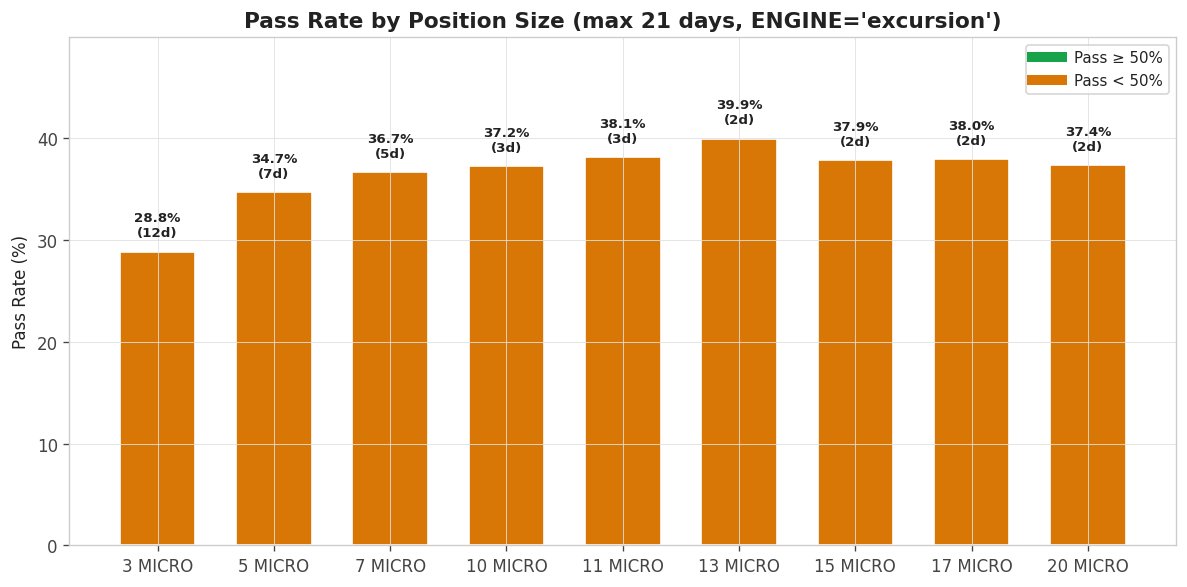

In [ ]:
# =========================================================
# CELL 9: CHARTS (engine-consistent)
# =========================================================
# * Spaghetti paths are generated with the SAME engine selected in Cell 6b
# (trade/excursion level), so the chart tells the same story as the
# tables. ENGINE="daily" falls back to Cell 6's simulate_paths.
# * Chart 4 reads the engine-agnostic key res["max_dds"].

# ── Override to white background ─────────────────────────
plt.rcParams.update({
    "figure.facecolor":  "white",
    "axes.facecolor":    "white",
    "axes.edgecolor":    "#cccccc",
    "axes.labelcolor":   "#222222",
    "axes.titleweight":  "bold",
    "axes.titlesize":    13,
    "axes.grid":         True,
    "grid.color":        "#e0e0e0",
    "grid.linewidth":    0.5,
    "text.color":        "#222222",
    "xtick.color":       "#444444",
    "ytick.color":       "#444444",
    "font.family":       "sans-serif",
    "font.size":         10,
    "legend.facecolor":  "white",
    "legend.edgecolor":  "#cccccc",
    "legend.fontsize":   9,
    "figure.dpi":        120,
})

ACCENT_GREEN  = "#16a34a"
ACCENT_RED    = "#dc2626"
ACCENT_ORANGE = "#d97706"
ACCENT_BLUE   = "#2563eb"
ACCENT_GRAY   = "#9ca3af"
ACCENT_PURPLE = "#7c3aed"
TEXT_COLOR     = "#222222"

# ── 1. Spaghetti chart (same engine as the tables) ──────
N_SPAGHETTI = 300

def _paths_current_engine(n_paths, n_contracts, rng, use_mae):
    """EOD equity paths under the Cell 6b engine (trade or excursion).
    Includes the same trade-resolution Daily Loss Limit model as CELL 6b
    (see its comments for the full rationale), so this chart's paths are
    consistent with the pass-rate table above -- CELL 6b's engine drives
    both, using the same TRADE_BAG path/MAE data."""
    P = np.full((n_paths, CHALLENGE.max_trading_days), np.nan)
    outs = []
    for i in range(n_paths):
        eq = hwm = 0.0
        td = 0
        out = None
        _maxd = draw_deadline(rng)
        _days = bootstrap_days(rng, len(TRADE_BAG), _maxd)
        for day in range(1, _maxd + 1):
            pnl, mae = TRADE_BAG[_days[day - 1]]
            if len(pnl):
                td += 1
            floor = hwm - CHALLENGE.max_drawdown
            if floor > CHALLENGE.dd_lock_profit:
                floor = CHALLENGE.dd_lock_profit
            day_open_eq = eq
            dll_floor = (day_open_eq - CHALLENGE.daily_loss_limit
                         if CHALLENGE.daily_loss_limit > 0 else -np.inf)
            dll_first = dll_floor > floor      # see CELL 6b
            for j in range(len(pnl)):
                if use_mae:
                    trough = eq - mae[j] * n_contracts
                    if dll_first:
                        if trough <= dll_floor:
                            eq = dll_floor
                            break
                    elif trough <= floor:
                        out = "fail_dd"
                        break
                eq += pnl[j] * n_contracts
                if dll_first:
                    if eq <= dll_floor:
                        eq = dll_floor
                        break
                elif eq <= floor:
                    out = "fail_dd"
                    break
                if (eq >= CHALLENGE.profit_target and
                        td >= CHALLENGE.min_trading_days):
                    out = "pass"
                    break
            P[i, day - 1] = eq
            if out:
                break
            if eq > hwm:
                hwm = eq
        outs.append(out or "fail_time")
    return P, outs

if ENGINE in ("trade", "excursion"):
    paths, outcomes = _paths_current_engine(
        N_SPAGHETTI, NUM_CONTRACTS,
        np.random.default_rng(SEED + 5000), use_mae=(ENGINE == "excursion"))
else:
    _pr = simulate_paths(daily_pool=daily_pool, challenge=CHALLENGE,
                         n_paths=N_SPAGHETTI, n_contracts=NUM_CONTRACTS,
                         rng=np.random.default_rng(SEED + 5000))
    paths, outcomes = _pr["paths"], _pr["outcomes"]

fig, ax = plt.subplots(figsize=(12, 5.5))
days_x = np.arange(1, CHALLENGE.max_trading_days + 1)

for i in range(N_SPAGHETTI):
    if outcomes[i] == "pass":
        ax.plot(days_x, paths[i], color=ACCENT_GREEN, alpha=0.18, linewidth=0.8)
    elif outcomes[i] == "fail_dd":
        ax.plot(days_x, paths[i], color=ACCENT_RED, alpha=0.18, linewidth=0.8)
    else:
        ax.plot(days_x, paths[i], color=ACCENT_GRAY, alpha=0.22, linewidth=0.8)

ax.axhline(CHALLENGE.profit_target, color=ACCENT_GREEN, linestyle="--", linewidth=1.8, alpha=0.9)
ax.axhline(-CHALLENGE.max_drawdown, color=ACCENT_RED, linestyle="--", linewidth=1.8, alpha=0.9)
ax.axhline(0, color="#aaaaaa", linewidth=0.6, alpha=0.5)

pass_pct = res["passed"]    / res["n_sims"]
dd_pct   = res["fail_dd"]   / res["n_sims"]
time_pct = res["fail_time"] / res["n_sims"]

legend_custom = [
    Line2D([0],[0], color=ACCENT_GREEN, linewidth=2, label=f"Passed ({pass_pct:.1%})"),
    Line2D([0],[0], color=ACCENT_RED,   linewidth=2, label=f"DD Fail ({dd_pct:.1%})"),
    Line2D([0],[0], color=ACCENT_GRAY,  linewidth=2, label=f"Time Fail ({time_pct:.1%})"),
    Line2D([0],[0], color=ACCENT_GREEN, linestyle="--", linewidth=1.5, label=f"Target ${CHALLENGE.profit_target:,.0f}"),
    Line2D([0],[0], color=ACCENT_RED,   linestyle="--", linewidth=1.5, label=f"DD Limit −${CHALLENGE.max_drawdown:,.0f}"),
]
ax.legend(handles=legend_custom, loc="upper left", framealpha=0.95)

ax.set_xlabel("Trading Day")
ax.set_ylabel("Equity ($)")
ax.set_title(f"Apex 50K EOD — Monte Carlo Equity Paths "
             f"({N_SPAGHETTI} sample paths, ENGINE={ENGINE!r}; "
             f"%s = {res['n_sims']:,} sims)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlim(1, CHALLENGE.max_trading_days)
plt.tight_layout()
plt.show()


# ── 2. Outcome donut ────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, 5))
sizes = [res["passed"], res["fail_dd"], res["fail_daily"], res["fail_time"]]
lbls  = ["Passed", "Fail: DD", "Fail: Daily Limit", "Fail: Time"]
cols  = [ACCENT_GREEN, ACCENT_RED, ACCENT_ORANGE, ACCENT_GRAY]

nz = [(s, l, c) for s, l, c in zip(sizes, lbls, cols) if s > 0]
if nz:
    s, l, c = zip(*nz)
    wedges, texts, autotexts = ax.pie(
        s, labels=l, colors=c, autopct="%1.1f%%", startangle=90,
        pctdistance=0.78, wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2.5),
        textprops={"fontsize": 10, "color": TEXT_COLOR},
    )
    for t in autotexts:
        t.set_fontsize(9)
        t.set_color("white")
        t.set_fontweight("bold")

ax.set_title(f"Apex 50K EOD — Outcome Breakdown\n({PROP_MC_SIMS:,} sims)", pad=15)
plt.tight_layout()
plt.show()


# ── 3. Days to pass histogram ───────────────────────────
dtp = res["days_to_pass"]
if len(dtp) > 0:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(dtp, bins=range(1, CHALLENGE.max_trading_days + 2),
            color=ACCENT_BLUE, edgecolor="white", linewidth=0.8, alpha=0.85)
    med = np.median(dtp)
    ax.axvline(med, color=ACCENT_ORANGE, linestyle="--", linewidth=2,
               label=f"Median: {med:.0f} days")
    ax.legend()
    ax.set_xlabel("Trading Days to Pass")
    ax.set_ylabel("Frequency")
    ax.set_title("Days to Pass Distribution")
    plt.tight_layout()
    plt.show()


# ── 4. Max DD distribution ──────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
dd = res["max_dds"] if "max_dds" in res else res["max_dds_all"]
ax.hist(dd, bins=60, color=ACCENT_PURPLE, edgecolor="white", linewidth=0.5, alpha=0.8)
ax.axvline(CHALLENGE.max_drawdown, color=ACCENT_RED, linestyle="--", linewidth=2,
           label=f"DD Limit: ${CHALLENGE.max_drawdown:,.0f}")
ax.axvline(np.median(dd), color=ACCENT_BLUE, linestyle="--", linewidth=1.5,
           label=f"Median: ${np.median(dd):,.0f}")
ax.legend()
ax.set_xlabel("Max Drawdown ($)")
ax.set_ylabel("Frequency")
ax.set_title(f"Max Drawdown Distribution (ENGINE={ENGINE!r})")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
plt.tight_layout()
plt.show()


# ── 5. Position size sweep ──────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
micros_list = [d["micros"] for d in sweep_data]
prs_s = [d["pr"] * 100 for d in sweep_data]
days_s = [d["days"] for d in sweep_data]

PASS_OK = 0.50
ok_mask = [d["pr"] >= PASS_OK for d in sweep_data]
bar_cols = [ACCENT_GREEN if ok else ACCENT_ORANGE for ok in ok_mask]
bars = ax.bar(range(len(micros_list)), prs_s, color=bar_cols, edgecolor="white", linewidth=1, width=0.65)
ax.set_xticks(range(len(micros_list)))
ax.set_xticklabels([f"{m} MICRO" for m in micros_list])
ax.set_ylabel("Pass Rate (%)")
ax.set_ylim(0, (max(prs_s) * 1.25) if (prs_s and max(prs_s) > 0) else 100)
ax.set_title(f"Pass Rate by Position Size (max {MAX_TRADING_DAYS} days, ENGINE={ENGINE!r})")
ax.axhline(50, color="#aaaaaa", linestyle="--", alpha=0.5)

for bar, val, d in zip(bars, prs_s, days_s):
    days_txt = f"{d:.0f}d" if not np.isnan(d) else "—"
    lbl = f"{val:.1f}%\n({days_txt})"
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2,
            lbl, ha="center", va="bottom", fontsize=8, color=TEXT_COLOR, fontweight="bold")

legend_sw = [
    Line2D([0],[0], color=ACCENT_GREEN,  linewidth=6, label=f"Pass ≥ {PASS_OK:.0%}"),
    Line2D([0],[0], color=ACCENT_ORANGE, linewidth=6, label=f"Pass < {PASS_OK:.0%}"),
]
ax.legend(handles=legend_sw, loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
# =========================================================
# CELL 10: FINAL SUMMARY
# =========================================================


ci = res["pass_rate_ci"]
pr = res["pass_rate"]
_sample_tag = (f"OOS from {pd.to_datetime(OOS_START_DATE).date()}"
               if OOS_START_DATE else "FULL sample")

print("\n" + "═" * 55)
print(f"  FINAL SUMMARY — {CHALLENGE.name}  ({_sample_tag})")
print("═" * 55)
print(f"  Contracts       : {NUM_CONTRACTS:g} MINI ({round(NUM_CONTRACTS*MICRO_PER_MINI)} MICRO)")
print(f"  Daily pool size : {len(daily_full)} weekdays ({daily_full['is_trade_day'].sum()} active)")
print(f"  Simulations     : {PROP_MC_SIMS:,}")
print(f"")
print(f"  Pass Rate       : {pr:.1%}  [{ci[0]:.1%} — {ci[1]:.1%}]")
if res["avg_days_to_pass"] is not None:
    print(f"  Avg Days to Pass: {res['avg_days_to_pass']:.1f}")
print(f"  Avg Max DD      : ${res['avg_max_dd']:,.0f}")
print(f"  P95 Max DD      : ${res['p95_max_dd']:,.0f}")

failures = {"DD": res["fail_dd"], "Daily Limit": res["fail_daily"], "Time Cap": res["fail_time"]}
primary = max(failures, key=failures.get)
if failures[primary] > 0:
    print(f"  #1 Failure Mode : {primary} ({failures[primary]/res['n_sims']:.1%})")

# ── Expected challenges to pass ──────────────────────────
if pr > 0:
    expected_n = 1 / pr
    print(f"\n  Expected challenges to pass 1 eval: {expected_n:.1f}")
else:
    print(f"\n  Expected challenges to pass 1 eval: ∞ (pass rate is 0)")

# ── Cumulative probability over N attempts ───────────────
print(f"\n  Cumulative pass probability (independent attempts assumed):")
print(f"  {'Challenges':>12}  {'P(pass ≥ 1)':>12}")
print(f"  {'─'*12}  {'─'*12}")
for n in [1, 2, 3, 4]:
    p_n = 1 - (1 - pr) ** n
    print(f"  {n:>12}  {p_n:>11.1%}")

# ── Verdict (single scale, defined in Cell 6) ────────────
_emoji = {"STRONG": "🟢", "SOLID": "🟡", "MODERATE": "🟠", "RISKY": "🔴", "POOR": "⛔"}
_msg = {"STRONG": "High probability, strategy well-suited.",
        "SOLID": "Good odds, minor tweaks may help.",
        "MODERATE": "Coin-flip territory, consider tighter risk.",
        "RISKY": "More likely to fail, reduce exposure.",
        "POOR": "Very low chance, major changes needed."}
_tag = verdict_tag(pr)
print(f"\n  {_emoji[_tag]} {_tag} — {_msg[_tag]}")

print("═" * 55)


═══════════════════════════════════════════════════════
  FINAL SUMMARY — Apex 50K EOD  (OOS from 2023-01-01)
═══════════════════════════════════════════════════════
  Contracts       : 1 MINI (10 MICRO)
  Daily pool size : 944 weekdays (922 active)
  Simulations     : 20,000

  Pass Rate       : 38.2%  [37.5% — 38.9%]
  Avg Days to Pass: 2.9
  Avg Max DD      : $1,999
  P95 Max DD      : $3,217
  #1 Failure Mode : DD (61.8%)

  Expected challenges to pass 1 eval: 2.6

  Cumulative pass probability (independent attempts assumed):
    Challenges   P(pass ≥ 1)
  ────────────  ────────────
             1        38.2%
             2        61.8%
             3        76.4%
             4        85.4%

  🟠 MODERATE — Coin-flip territory, consider tighter risk.
═══════════════════════════════════════════════════════


In [ ]:
# =========================================================
# CELL 10b: CUMULATIVE PASS PROBABILITY UNDER CORRELATED ATTEMPTS
# =========================================================
# P(at least one pass in n attempts). Naive: attempts as independent coins,
# 1-(1-p)^n. Correlated: attempts share persistent fate (true edge, regime,
# measurement optimism) - Beta mixture with attempt correlation rho:
#   P(all n fail) = prod_{k<n} (b+k)/(a+b+k),
#   a = p(1-rho)/rho, b = (1-p)(1-rho)/rho.
# Uses the holdout pass rate from the Cell 8 sweep when the split is on,
# else the main run.

RHO_GRID    = [0.0, 0.15, 0.30, 0.50]
N_MAX_ATT   = 6
ATTEMPT_FEE = 100.0        # one 50K eval attempt - EDIT to your real price

_p_att = (_val["pass_rate"] if "_val" in dir()
          else res["pass_rate"])
_fee_att = ATTEMPT_FEE

def _p_within_n(p, n, rho):
    if rho <= 0:
        return 1 - (1 - p) ** n
    a = p * (1 - rho) / rho
    b = (1 - p) * (1 - rho) / rho
    f = 1.0
    for k in range(n):
        f *= (b + k) / (a + b + k)
    return 1 - f

print("═" * 74)
print(f"  PASSING WITHIN N ATTEMPTS - p = {_p_att:.1%} per attempt")
print(f"  (rho = persistent share of fate between attempts; rho=0 is the")
print(f"  independence assumption every naive calculator uses)")
print("═" * 74)
_hdr = "".join(f"{'ρ=' + format(r, 'g'):>10}" for r in RHO_GRID)
print(f"  {'Attempts':>9} {'Fees':>8}" + _hdr)
print("  " + "─" * (19 + 10 * len(RHO_GRID)))
for n in range(1, N_MAX_ATT + 1):
    row = "".join(f"{_p_within_n(_p_att, n, r):>10.1%}" for r in RHO_GRID)
    print(f"  {n:>9} {'$' + format(n * _fee_att, ',.0f'):>8}" + row)

fig, ax = plt.subplots(figsize=(9, 4.6))
_ns = list(range(1, N_MAX_ATT + 1))
_cols = ["#9ca3af", "#60a5fa", "#2563eb", "#1e3a8a"]
for r, c in zip(RHO_GRID, _cols):
    ax.plot(_ns, [_p_within_n(_p_att, n, r) * 100 for n in _ns], "-o",
            color=c, linewidth=2 if r == 0.30 else 1.3,
            label=f"ρ = {r:g}" + ("  (independent)" if r == 0 else ""))
ax.set_xticks(_ns); ax.set_ylim(0, 100)
ax.set_xlabel("Number of attempts")
ax.set_ylabel("P(at least one pass) (%)")
ax.set_title("Cumulative pass probability vs attempt correlation\n"
             "(the fan between the curves is what persistence costs)", pad=12)
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

_n80 = {r: next((n for n in _ns if _p_within_n(_p_att, n, r) >= 0.80), None)
        for r in RHO_GRID}
print(f"\n  Attempts to reach 80% confidence: "
      + ",  ".join(f"ρ={r:g}: {(_n80[r] if _n80[r] else '>' + str(N_MAX_ATT))}"
                   for r in RHO_GRID))
print(f"  Budget at ρ=0.30, decided BEFORE attempt one: "
      f"{_n80[0.30] if _n80[0.30] else '>' + str(N_MAX_ATT)} fees"
      + (f" = ${_n80[0.30] * _fee_att:,.0f}" if _n80[0.30] and _fee_att else ""))
print(f"  Repeated failures are partly the SAME verdict repeating: after two,")
print(f"  diagnose the equity paths against the simulation before rebuying.")

---
## Funded Account — Optimal Position Sizing
**You passed the eval. What size should you trade on the Performance Account to maximise what you actually extract?**

Apex 4.0 rules (50K EOD):
- EOD trailing drawdown (\$2,500), locks at +\$100 — breach = account gone, payouts kept
- Payout gates, every cycle: 5 qualifying days (\$250+), best day < 50% of cycle profit, balance above the \$2,600 min-balance threshold (safety net \$2,100) safety net
- Payout ladder: \$1,500 → \$3,000 per request, 6 payouts max (\$13,000 ceiling), 100% split
- Inactivity: 2 days of \$50+ profit per rolling 30 days, or the account closes
- No deadline — accounts run until paid out, blown, or inactive

In [ ]:
# =========================================================
# CELL 11: FUNDED ACCOUNT - PAYOUT SIMULATION ENGINE
# =========================================================


import numpy as np

# --- Which rule set -------------------------------------------------
RULE_SET = "apex40"        # "apex40" or "legacy"

# --- 50K EOD PA parameters ------------------------------------------
if RULE_SET == "apex40":
    PAYOUT_QUAL_DAYS   = 5          # qualifying days needed
    PAYOUT_DAY_THR     = 250.0      # $ per qualifying day, 50K EOD
    PAYOUT_MIN_TRADED  = 0          # no separate trading-day count in 4.0
    CONSISTENCY_LIMIT  = 0.50       # max share of profit from one day
    PAYOUT_CAP         = 1500.0     # first payout cap, 50K EOD ladder
else:                                # legacy
    PAYOUT_QUAL_DAYS   = 5          # of the 8, at least 5 profitable
    PAYOUT_DAY_THR     = 50.0
    PAYOUT_MIN_TRADED  = 8          # trading days since last request
    CONSISTENCY_LIMIT  = 0.30
    PAYOUT_CAP         = 1500.0

PAYOUT_MIN_BALANCE    = 2600.0   # min balance to REQUEST a payout ("Min Balance
                                 # to Request" = $52,600 on a 50K)
PAYOUT_MIN_WITHDRAWAL = 500.0    # minimum payout request
# "Safety Net" and "Min Balance to Request" are two DIFFERENT numbers:
#   PAYOUT_MIN_BALANCE (2,600) = eligibility. The balance must reach it before
#                                the payout request option appears.
#   PAYOUT_SAFETY_NET  (2,100) = the floor the balance may not end up below
#                                after a withdrawal (= max drawdown + 100).
# Apex's worked example: at exactly $52,600 you can request the $500 minimum,
# leaving $52,100 - the minimum payout is allowed to encroach on the safety net
# by that much, nothing more. Anything printed as "safety net" must use
# PAYOUT_SAFETY_NET. Source: apextraderfunding.com/help-center/
# eod-trailing-drawdown-accounts/eod-payouts/
PAYOUT_SAFETY_NET     = PAYOUT_MIN_BALANCE - PAYOUT_MIN_WITHDRAWAL   # = 2,100
PAYOUT_MAX_DD         = CHALLENGE.max_drawdown   # $2,000 EOD trailing
# The PA Daily Loss Limit ($1,000, see CELL 6b) is modelled at trade resolution
# from TRADE_BAG, not at day resolution:
#   - A day-level cap on realised P&L is not a DLL. It clips days that closed
#     below -DLL but cannot catch days that touched -DLL intraday and then
#     recovered, which a real DLL would have liquidated before the recovery.
#     That one-sided clip pins the downside at a size-independent constant
#     while the upside keeps scaling, which makes larger sizes look safer.
#   - TRADE_BAG (CELL 6b, same source data and business-day grid as daily_pool)
#     carries the intratrade MAE path, so the DLL can be checked the way Apex
#     enforces it: from the day's open equity, against the intratrade trough,
#     liquidating for the day rather than failing the account.
#   - Degraded stress-test runs use the SAME engine. Degradation is applied to
#     the trades (apply_trade_degradation, CELL 6), not to day aggregates, so
#     baseline and degraded runs differ only in the data. Switching engines
#     between scenarios would put an engine change inside every measured
#     degradation effect.
PAYOUT_DD_LOCK        = 100.0                  # threshold stops at start + $100
PAYOUT_SPLIT          = 1.00
INACTIVITY_WINDOW_TD  = 22                     # ~30 calendar days in trading days
INACTIVITY_MIN_QUAL   = 2                      # qualifying days per rolling window
INACTIVITY_PROFIT_THR = 50.0                   # qualifying day = net profit >= $50
INACTIVITY_ON         = True                   # False disables the rule
PAYOUT_MAX_HORIZON    = 250                    # guard, ~1 trading year. NOT a rule.
PAYOUT_SIMS           = 20_000
PAYOUT_SWEEP_SIMS     = 5_000

PAYOUT_CONTRACTS = [
    0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9,
    1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.7, 2.0,
]
# NOTE: 4.0 PAs have tier-based contract scaling (a 50K eval allows 6 but the
# PA starts you at 2 minis). The top of this grid sits at that day-one limit.


def simulate_funded(daily_pool, n_sims, n_contracts, rng,
                    degrade_wr=0.0, degrade_pnl=0.0,
                    dd_lock_profit=PAYOUT_DD_LOCK, deg_seed=20240101,
                    max_horizon=PAYOUT_MAX_HORIZON,
                    inactivity_on=INACTIVITY_ON):
    # One engine for every scenario: TRADE_BAG at trade resolution, DLL modeled.
    # Degradation is applied to the trades, not by switching engines.
    bag = apply_trade_degradation(TRADE_BAG, degrade_wr, degrade_pnl, deg_seed)

    qualified = blown = timeout = closed_inactive = 0
    payouts, max_dds, days_to_qual = [], [], []
    blocked_by = {"qual_days": 0, "safety_net": 0, "consistency": 0}

    _min_equity_ok = PAYOUT_MIN_BALANCE   # eligibility is the Min-Balance-to-
                                          # Request threshold itself, not +$500

    for _ in range(n_sims):
        equity = eod_hwm = sim_max_dd = 0.0
        best_day = 0.0          # largest single profitable day
        qual_days = 0           # days clearing PAYOUT_DAY_THR
        trade_days = 0
        act_q1 = act_q2 = 0     # day indices of the 2 most recent $50+ profit days
        outcome = None

        _days = bootstrap_days(rng, len(bag), max_horizon)
        for day in range(max_horizon):
            # --- trailing threshold for THIS day, fixed at the day's start ---
            floor = eod_hwm - PAYOUT_MAX_DD
            if floor > dd_lock_profit:      # threshold stops trailing at the lock
                floor = dd_lock_profit

            pnl, mae = bag[_days[day]]
            has_trades = len(pnl) > 0
            dll_floor = (equity - CHALLENGE.daily_loss_limit
                         if CHALLENGE.daily_loss_limit > 0 else -np.inf)
            dll_first = dll_floor > floor      # see CELL 6b
            day_start_equity = equity
            day_trough = equity                # lowest point touched today
            day_blown = False
            for j in range(len(pnl)):
                # USE_MAE comes from CELL 6b: with ENGINE='trade'/'daily' the MAE is
                # not used, and trough collapses to the pre-trade equity (a no-op).
                trough = equity - (mae[j] * n_contracts if USE_MAE else 0.0)
                day_trough = min(day_trough, trough)
                if dll_first:
                    if trough <= dll_floor:
                        equity = dll_floor
                        break
                elif trough <= floor:
                    day_blown = True
                    break
                equity += pnl[j] * n_contracts
                day_trough = min(day_trough, equity)
                if dll_first:
                    if equity <= dll_floor:
                        equity = dll_floor
                        break
                elif equity <= floor:
                    day_blown = True
                    break
            day_pnl = equity - day_start_equity

            if has_trades:
                trade_days += 1
            # rolling inactivity: 2 days of >= $50 profit per ~30 calendar days
            if day_pnl >= INACTIVITY_PROFIT_THR:
                act_q2, act_q1 = act_q1, day
            elif inactivity_on and (day - act_q2 >= INACTIVITY_WINDOW_TD):
                outcome = "closed_inactive"
                break
            if day_pnl >= PAYOUT_DAY_THR:            # >=: exactly $250 counts
                qual_days += 1
            if day_pnl > best_day:
                best_day = day_pnl

            # intraday trough is measurable at trade resolution, so use it
            sim_max_dd = max(sim_max_dd, eod_hwm - day_trough)

            if day_blown or equity <= floor:
                outcome = "blown"
                break

            if equity > eod_hwm:
                eod_hwm = equity

            # --- payout eligibility, tested every day, no deadline ---
            days_ok   = (qual_days >= PAYOUT_QUAL_DAYS
                         and trade_days >= PAYOUT_MIN_TRADED)
            net_ok    = equity >= _min_equity_ok     # balance clears Min Balance to Request
            # (the old `equity <= 0 or ...` escape was dead: net_ok already
            # requires equity >= PAYOUT_MIN_BALANCE before this is reached)
            consis_ok = best_day < CONSISTENCY_LIMIT * equity

            if days_ok and net_ok and consis_ok:
                outcome = "qualified"
                days_to_qual.append(day + 1)
                break

        max_dds.append(sim_max_dd)

        if outcome == "blown":
            blown += 1
        elif outcome == "closed_inactive":
            closed_inactive += 1
        elif outcome == "qualified":
            qualified += 1
            # withdrawable = profit above the Safety Net leave-behind floor
            # ($2,100), not above the Min-Balance-to-Request threshold ($2,600).
            payouts.append(min((equity - PAYOUT_SAFETY_NET) * PAYOUT_SPLIT,
                               PAYOUT_CAP))
        else:
            timeout += 1
            # which condition was still outstanding when time ran out
            if qual_days < PAYOUT_QUAL_DAYS or trade_days < PAYOUT_MIN_TRADED:
                blocked_by["qual_days"] += 1
            elif equity < _min_equity_ok:
                blocked_by["safety_net"] += 1
            else:
                blocked_by["consistency"] += 1

    qr = qualified / n_sims
    avg_pay = float(np.mean(payouts)) if payouts else 0.0
    med_pay = float(np.median(payouts)) if payouts else 0.0

    return {
        "n_contracts": n_contracts, "micros": int(round(n_contracts * MICRO_PER_MINI)),
        "qualified": qualified, "blown": blown,
        "closed_inactive": closed_inactive,
        "rule_fail": timeout,                      # kept for Cells 13/14
        "timeout": timeout,
        "qualify_rate": qr, "qualify_ci": wilson_ci(qualified, n_sims),
        "blown_rate": blown / n_sims,
        "closed_inactive_rate": closed_inactive / n_sims,
        "rule_fail_rate": timeout / n_sims,
        "timeout_rate": timeout / n_sims,
        "blocked_by": blocked_by,
        "median_days_to_qualify": float(np.median(days_to_qual)) if days_to_qual else np.nan,
        "p90_days_to_qualify": float(np.percentile(days_to_qual, 90)) if days_to_qual else np.nan,
        "avg_payout": avg_pay, "median_payout": med_pay,
        "expected_payout": qr * avg_pay,
        "p10_payout": float(np.percentile(payouts, 10)) if payouts else 0.0,
        "p90_payout": float(np.percentile(payouts, 90)) if payouts else 0.0,
        "payouts": np.array(payouts),
        "max_dds": np.array(max_dds),
        "days_to_qualify": np.array(days_to_qual),
    }


print("Funded account simulation engine v4 loaded.")
print(f"   Rule set: {RULE_SET} | qualifying days: {PAYOUT_QUAL_DAYS} "
      f"at >=${PAYOUT_DAY_THR:.0f}" +
      (f" | min traded days: {PAYOUT_MIN_TRADED}" if PAYOUT_MIN_TRADED else ""))
print(f"   Min balance to request: +${PAYOUT_MIN_BALANCE:,.0f} | withdrawable = profit - "
      f"${PAYOUT_SAFETY_NET:,.0f} (Safety Net; min ${PAYOUT_MIN_WITHDRAWAL:,.0f} payout "
      f"allowed to dip into it) | consistency: "
      f"{CONSISTENCY_LIMIT:.0%} | payout cap: ${PAYOUT_CAP:,.0f}")
print(f"   Max DD: ${PAYOUT_MAX_DD:,.0f} EOD trailing, locks at "
      f"+${PAYOUT_DD_LOCK:,.0f} | horizon guard: {PAYOUT_MAX_HORIZON} days")
print(f"   Inactivity: {INACTIVITY_MIN_QUAL} days of >=${INACTIVITY_PROFIT_THR:.0f} "
      f"net profit per rolling 30 calendar days (Apex support docs); "
      f"modeled as {INACTIVITY_WINDOW_TD} trading days" if INACTIVITY_ON
      else "   Inactivity rule: disabled")
print("   No deadline on qualifying days - accounts run until qualified, "
      "blown, or closed for inactivity.")

Funded account simulation engine v4 loaded.
   Rule set: apex40 | qualifying days: 5 at >=$250
   Min balance to request: +$2,600 | withdrawable = profit - $2,100 (Safety Net; min $500 payout allowed to dip into it) | consistency: 50% | payout cap: $1,500
   Max DD: $2,000 EOD trailing, locks at +$100 | horizon guard: 250 days
   Inactivity: 2 days of >=$50 net profit per rolling 30 calendar days (Apex support docs); modeled as 22 trading days
   No deadline on qualifying days - accounts run until qualified, blown, or closed for inactivity.


In [ ]:
# =========================================================
# CELL 12: FUNDED ACCOUNT — CONTRACT SIZE SWEEP
# =========================================================

# Cost incurred each time the funded account is LOST (blown or closed inactive):
# replacement eval(s) + PA activation + lost time.
BLOWN_COST     = 150.0
# Sizes with a higher blow-up rate than this are excluded from the "optimal" pick.
MAX_BLOWN_RATE = 0.50

print("\n" + "═" * 86)
print("  FUNDED ACCOUNT — POSITION SIZE SWEEP")
print("═" * 86)
print(f"  {'MICRO':>5} {'Qualify%':>9} {'Blown%':>8} {'Inact%':>8} {'AtHorizon%':>11} "
      f"{'AvgPay':>8} {'E[Pay]':>8} {'E[net]':>8}")
print("  " + "─" * 82)

payout_sweep = []

for nc in PAYOUT_CONTRACTS:
    r = simulate_funded(
        daily_pool=daily_pool, n_sims=PAYOUT_SWEEP_SIMS,
        n_contracts=nc, rng=np.random.default_rng(SEED + 8000),
    )
    # Net EV: every lost account (blown OR inactive) costs its replacement
    _closure_rate = r["blown_rate"] + r["closed_inactive_rate"]
    r["net_ev"] = r["expected_payout"] - _closure_rate * BLOWN_COST
    print(f"  {r['micros']:>4}x {r['qualify_rate']:>9.1%} {r['blown_rate']:>8.1%} "
          f"{r['closed_inactive_rate']:>8.1%} {r['rule_fail_rate']:>11.1%} "
          f"{'$' + format(r['avg_payout'], ',.0f'):>8} "
          f"{'$' + format(r['expected_payout'], ',.0f'):>8} "
          f"{'$' + format(r['net_ev'], ',.0f'):>8}")
    payout_sweep.append(r)

# Best by net EV, among sizes within the blow-up tolerance.
candidates = [r for r in payout_sweep if r["blown_rate"] <= MAX_BLOWN_RATE] or payout_sweep
best = max(candidates, key=lambda x: x["net_ev"])
print(f"\n  >>> OPTIMAL (net EV, blown ≤ {MAX_BLOWN_RATE:.0%}): {best['micros']} MICRO → "
      f"E[net] ${best['net_ev']:,.0f}  (gross E[Pay] ${best['expected_payout']:,.0f}, "
      f"qualify {best['qualify_rate']:.1%}, blown {best['blown_rate']:.1%}, "
      f"inactive {best['closed_inactive_rate']:.1%}) <<<")
print(f"      NOTE: EV of the FIRST payout only. Lifetime EV including payouts 2-6 "
      f"is computed in CELL 15,")
print(f"      which is the number the final recommendation (CELL 16) uses.")


══════════════════════════════════════════════════════════════════════════════════════
  FUNDED ACCOUNT — POSITION SIZE SWEEP
══════════════════════════════════════════════════════════════════════════════════════
  MICRO  Qualify%   Blown%   Inact%  AtHorizon%   AvgPay   E[Pay]   E[net]
  ──────────────────────────────────────────────────────────────────────────────────
     2x     63.8%    36.2%     0.0%        0.0%     $801     $511     $457
     3x     52.6%    47.4%     0.0%        0.0%   $1,060     $558     $487
     4x     45.0%    55.0%     0.0%        0.0%   $1,308     $588     $505
     5x     39.1%    60.9%     0.0%        0.0%   $1,445     $565     $474
     6x     36.8%    63.2%     0.0%        0.0%   $1,483     $546     $451
     7x     32.5%    67.5%     0.0%        0.0%   $1,490     $484     $382
     8x     29.6%    70.4%     0.0%        0.0%   $1,497     $442     $337
     9x     28.3%    71.7%     0.0%        0.0%   $1,499     $424     $317
    10x     26.4%    73.6%

In [ ]:
# =========================================================
# CELL 13: FUNDED ACCOUNT — DETAIL AT OPTIMAL SIZE
# =========================================================

best_nc  = best["n_contracts"]
best_micros = best["micros"]

detail = simulate_funded(
    daily_pool=daily_pool, n_sims=PAYOUT_SIMS,
    n_contracts=best_nc, rng=np.random.default_rng(SEED + 9000),
)

ci = detail["qualify_ci"]
_sample_tag = (f"OOS from {pd.to_datetime(OOS_START_DATE).date()}"
               if OOS_START_DATE else "FULL sample")

print("\n" + "═" * 60)
print(f"  FUNDED ACCOUNT DETAIL — {best_micros} MICRO ({best_nc:g} MINI)  ({_sample_tag})")
print("═" * 60)
print(f"  Simulations     : {PAYOUT_SIMS:,}")
print(f"  Qualify Rate    : {detail['qualify_rate']:.1%}  [{ci[0]:.1%} — {ci[1]:.1%}]")
print(f"  Blown (DD)      : {detail['blown_rate']:.1%}")
print(f"  Closed (inactive): {detail['closed_inactive_rate']:.1%}")
print(f"  Rule Fail       : {detail['rule_fail_rate']:.1%}")
print(f"")
print(f"  Median days to qualify : {detail['median_days_to_qualify']:.0f}")
print(f"  P90 days to qualify    : {detail['p90_days_to_qualify']:.0f}")
print(f"")
print(f"  Avg Payout      : ${detail['avg_payout']:,.0f}")
print(f"  Median Payout   : ${detail['median_payout']:,.0f}")
print(f"  P10 Payout      : ${detail['p10_payout']:,.0f}")
print(f"  P90 Payout      : ${detail['p90_payout']:,.0f}")
print(f"  Expected Payout : ${detail['expected_payout']:,.0f}")
print(f"  (Expected = qualify rate x avg payout; first payout of the ladder only.)")


════════════════════════════════════════════════════════════
  FUNDED ACCOUNT DETAIL — 3 MICRO (0.3 MINI)  (OOS from 2023-01-01)
════════════════════════════════════════════════════════════
  Simulations     : 20,000
  Qualify Rate    : 51.2%  [50.6% — 51.9%]
  Blown (DD)      : 48.8%
  Closed (inactive): 0.0%
  Rule Fail       : 0.0%

  Median days to qualify : 12
  P90 days to qualify    : 21

  Avg Payout      : $1,049
  Median Payout   : $1,026
  P10 Payout      : $589
  P90 Payout      : $1,500
  Expected Payout : $537
  (Expected = qualify rate x avg payout; first payout of the ladder only.)


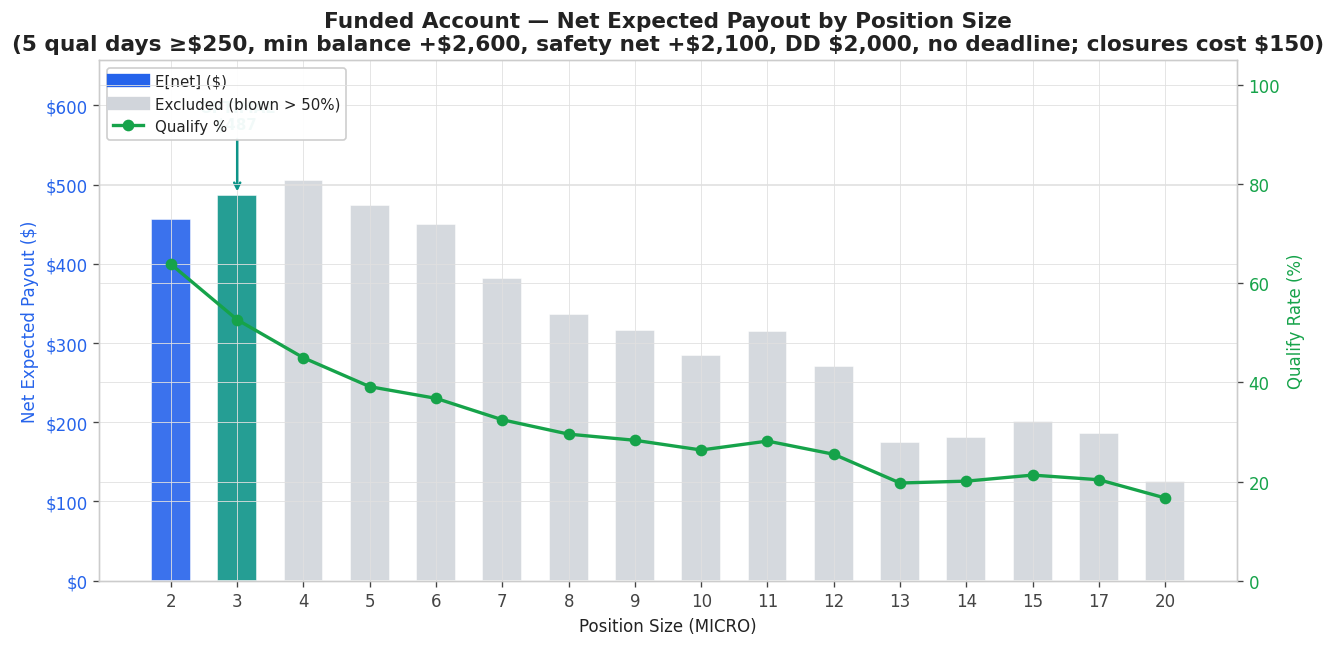

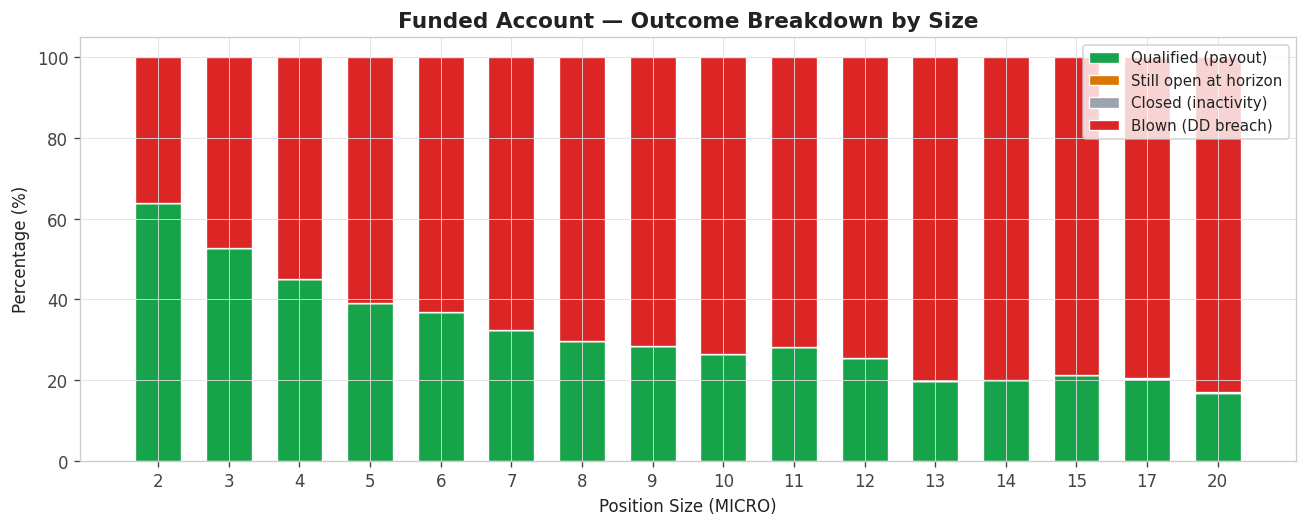

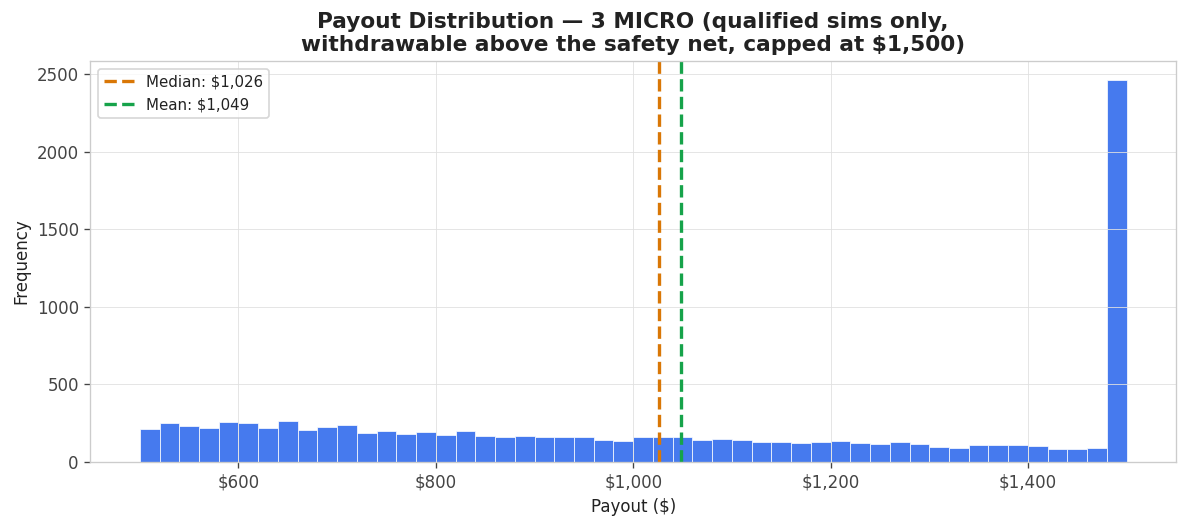

In [ ]:
# =========================================================
# CELL 14: FUNDED ACCOUNT — CHARTS
# =========================================================
# * text.parse_math disabled: matplotlib no longer treats paired $...$ as
# math, so dollar amounts render literally with no escaping needed
# (this is what garbled the old titles).
# * Chart 1: y-axis headroom so the OPTIMAL annotation cannot overlap the
# title; sizes excluded by MAX_BLOWN_RATE drawn in light gray with their
# own legend entry, so it is visible WHY a taller bar can lose to the
# highlighted one.
# * Chart 2: "Rule fail" renamed "Still open at horizon" - with no
# deadline it only counts sims alive at the simulation guard, ~0%.

plt.rcParams["text.parse_math"] = False   # dollar signs are dollar signs

ACCENT_GREEN  = "#16a34a"
ACCENT_RED    = "#dc2626"
ACCENT_ORANGE = "#d97706"
ACCENT_BLUE   = "#2563eb"
ACCENT_GRAY   = "#9ca3af"
ACCENT_TEAL   = "#0d9488"
EXCLUDED_GRAY = "#d1d5db"
TEXT_COLOR     = "#222222"


# ── 1. Net Expected Payout vs Size (dual-axis) ─────────
fig, ax1 = plt.subplots(figsize=(11, 5.5))

micros_list   = [d["micros"] for d in payout_sweep]
nevs   = [d["net_ev"] for d in payout_sweep]
qrs    = [d["qualify_rate"] * 100 for d in payout_sweep]
excl   = [d["blown_rate"] > MAX_BLOWN_RATE for d in payout_sweep]

best_idx = [d["n_contracts"] for d in payout_sweep].index(best["n_contracts"])
bar_colors = [ACCENT_TEAL if i == best_idx
              else (EXCLUDED_GRAY if excl[i] else ACCENT_BLUE)
              for i in range(len(micros_list))]
bars = ax1.bar(range(len(micros_list)), nevs, color=bar_colors, edgecolor="white",
               linewidth=1, width=0.6, alpha=0.9)
ax1.set_xticks(range(len(micros_list)))
ax1.set_xticklabels([f"{m}" for m in micros_list])
ax1.set_xlabel("Position Size (MICRO)")
ax1.set_ylabel("Net Expected Payout ($)", color=ACCENT_BLUE)
ax1.tick_params(axis="y", labelcolor=ACCENT_BLUE)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))

# headroom so the annotation sits inside the axes, clear of the title
_top = max(nevs) if (nevs and max(nevs) > 0) else 1.0
ax1.set_ylim(0, _top * 1.30)

_ev_best = nevs[best_idx]
ax1.annotate(f"OPTIMAL\n${_ev_best:,.0f}",
             xy=(best_idx, _ev_best),
             xytext=(best_idx, _top * 1.12),
             fontsize=9, fontweight="bold", color=ACCENT_TEAL,
             ha="center", va="bottom",
             arrowprops=dict(arrowstyle="->", color=ACCENT_TEAL, lw=1.5))

ax2 = ax1.twinx()
ax2.plot(range(len(micros_list)), qrs, color=ACCENT_GREEN, marker="o", linewidth=2,
         markersize=6, label="Qualify %", zorder=5)
ax2.set_ylabel("Qualify Rate (%)", color=ACCENT_GREEN)
ax2.tick_params(axis="y", labelcolor=ACCENT_GREEN)
ax2.set_ylim(0, 105)

legend_custom = [
    Line2D([0], [0], color=ACCENT_BLUE, linewidth=8, label="E[net] ($)"),
    Line2D([0], [0], color=EXCLUDED_GRAY, linewidth=8,
           label=f"Excluded (blown > {MAX_BLOWN_RATE:.0%})"),
    Line2D([0], [0], color=ACCENT_GREEN, marker="o", linewidth=2, label="Qualify %"),
]
ax1.legend(handles=legend_custom, loc="upper left", framealpha=0.95)

ax1.set_title(f"Funded Account — Net Expected Payout by Position Size\n"
              f"({PAYOUT_QUAL_DAYS} qual days ≥${PAYOUT_DAY_THR:.0f}, "
              f"min balance +${PAYOUT_MIN_BALANCE:,.0f}, safety net "
      f"+${PAYOUT_SAFETY_NET:,.0f}, DD ${PAYOUT_MAX_DD:,.0f}, "
              f"no deadline; closures cost ${BLOWN_COST:,.0f})")
fig.tight_layout()
plt.show()


# ── 2. Outcome breakdown stacked bar ───────────────────
fig, ax = plt.subplots(figsize=(11, 4.5))

qr_vals = [d["qualify_rate"] * 100 for d in payout_sweep]
rf_vals = [d["rule_fail_rate"] * 100 for d in payout_sweep]
in_vals = [d["closed_inactive_rate"] * 100 for d in payout_sweep]
bl_vals = [d["blown_rate"] * 100 for d in payout_sweep]

x = range(len(micros_list))
ax.bar(x, qr_vals, color=ACCENT_GREEN, edgecolor="white", linewidth=0.8,
       width=0.65, label="Qualified (payout)")
ax.bar(x, rf_vals, bottom=qr_vals, color=ACCENT_ORANGE, edgecolor="white",
       linewidth=0.8, width=0.65, label="Still open at horizon")
ax.bar(x, in_vals, bottom=[q+r for q, r in zip(qr_vals, rf_vals)],
       color=ACCENT_GRAY, edgecolor="white", linewidth=0.8, width=0.65,
       label="Closed (inactivity)")
ax.bar(x, bl_vals, bottom=[q+r+i for q, r, i in zip(qr_vals, rf_vals, in_vals)],
       color=ACCENT_RED, edgecolor="white", linewidth=0.8, width=0.65,
       label="Blown (DD breach)")

ax.set_xticks(list(x))
ax.set_xticklabels([f"{m}" for m in micros_list])
ax.set_xlabel("Position Size (MICRO)")
ax.set_ylabel("Percentage (%)")
ax.set_title("Funded Account — Outcome Breakdown by Size")
ax.legend(loc="upper right")
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()


# ── 3. Payout distribution at optimal size ─────────────
payouts_arr = detail["payouts"]
if len(payouts_arr) > 0:
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.hist(payouts_arr, bins=50, color=ACCENT_BLUE, edgecolor="white",
            linewidth=0.5, alpha=0.85)
    med = np.median(payouts_arr)
    avg = np.mean(payouts_arr)
    ax.axvline(med, color=ACCENT_ORANGE, linestyle="--", linewidth=2,
               label=f"Median: ${med:,.0f}")
    ax.axvline(avg, color=ACCENT_GREEN, linestyle="--", linewidth=2,
               label=f"Mean: ${avg:,.0f}")
    ax.legend()
    ax.set_xlabel("Payout ($)")
    ax.set_ylabel("Frequency")
    ax.set_title(f"Payout Distribution — {best_micros} MICRO (qualified sims only,\n"
                 f"withdrawable above the safety net, capped at ${PAYOUT_CAP:,.0f})")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    plt.tight_layout()
    plt.show()

In [ ]:
# =========================================================
# CELL 15: FUNDED ACCOUNT - FULL LIFETIME (LADDER) SIMULATION
# =========================================================
# Simulates the ENTIRE Performance Account life under Apex 4.0:
# * Payout ladder 50K EOD: $1,500 / $1,500 / $2,000 / $2,500 / $2,500 / $3,000
# - 6 payouts max, then the account CLOSES by rule ($13,000 ceiling).
# * Each payout cycle restarts the gates: 5 NEW qualifying days (>= $250),
# consistency (best day < 50% of profit SINCE LAST PAYOUT), balance above
# the safety net with >= $500 withdrawable.
# * A withdrawal reduces the balance; the trailing threshold stays LOCKED at
# +$100 once reached (it never un-trails), so every payout knocks the
# buffer back toward $2,500 and the next cycle is a fresh survival run.
# * Inactivity (Apex support docs): 2 days with $50+ net profit per rolling
# 30 calendar days or the PA is permanently closed - modeled as 2
# qualifying days per trailing 22 trading days.
# * Blown / inactivity-closed accounts KEEP the payouts already taken -
# that is the whole point of lifetime EV.
# * Withdrawal policy modeled: request as soon as eligible, take
# min(balance above net, ladder cap). VERIFY on the dashboard that the
# balance may sit exactly at the net after withdrawal.
# Headline metric: E[total extraction] per account (max $13,000).

PAYOUT_LADDER = [1500.0, 1500.0, 2000.0, 2500.0, 2500.0, 3000.0]  # 50K EOD
LIFETIME_HORIZON = 2000         # guard, ~8 trading years. NOT a rule.
# RAISED from 500. E[total extraction] is only a lifetime expectation if almost
# every account has resolved (blown, closed, or ladder done) inside the horizon.
# Accounts still alive at the guard are counted as "horizon" and contribute only
# the payouts they had taken by then, so a short guard truncates the right tail --
# and it truncates it HARDEST at small sizes, which survive longest and need the
# most days to walk the ladder. Measured on the test pool: at 0.2 the guard cut
# E[total] by 7% ($5,678 vs $6,078) with 18% of accounts still alive at day 500,
# while every size at or above 0.3 moved less than 2%. That bias runs against the
# smallest sizes, i.e. against exactly the sizes this sweep tends to pick.
# Results are converged at 2000 (identical to 5000) and runtime is unchanged --
# accounts that die, die early.
# ALWAYS read horizon_rate in the sweep output: if it is not near zero, E[total]
# is still truncated and the number is a floor, not an expectation.
LIFETIME_SIMS = 10_000
LIFETIME_SWEEP_SIMS = 4_000


def simulate_funded_lifetime(daily_pool, n_sims, n_contracts, rng,
                             ladder=PAYOUT_LADDER,
                             degrade_wr=0.0, degrade_pnl=0.0,
                             deg_seed=20240101,
                             max_horizon=LIFETIME_HORIZON,
                             inactivity_on=INACTIVITY_ON):
    # baseline runs draw from
    # TRADE_BAG for a trade-resolution, DLL-aware day result; degraded
    # stress-test runs keep using the day-level pool. See CELL 11's note
    # for the full rationale (removing DLL was the optimistic choice, not
    # the conservative one).
    # One engine for every scenario: TRADE_BAG at trade resolution, DLL modeled.
    # Degradation is applied to the trades, not by switching engines.
    bag = apply_trade_degradation(TRADE_BAG, degrade_wr, degrade_pnl, deg_seed)

    totals, n_payouts_all, days_alive_all = [], [], []
    outcome_ct = {"ladder_done": 0, "blown": 0, "closed_inactive": 0, "horizon": 0}
    first_payout_days = []

    for _ in range(n_sims):
        equity = eod_hwm = 0.0
        locked = False
        act_q1 = act_q2 = 0     # day indices of the 2 most recent $50+ profit days
        # per-cycle state (resets after every payout)
        cyc_start = 0.0          # equity at start of the current payout cycle
        best_day = 0.0
        qual_days = 0
        payout_i = 0             # index into the ladder
        total_paid = 0.0
        outcome = None
        day = 0

        _days = bootstrap_days(rng, len(bag), max_horizon)
        for day in range(1, max_horizon + 1):
            # trailing threshold vs PREVIOUS hwm; locks permanently at +$100
            if locked:
                floor = PAYOUT_DD_LOCK
            else:
                floor = eod_hwm - PAYOUT_MAX_DD
                if floor >= PAYOUT_DD_LOCK:
                    locked = True
                    floor = PAYOUT_DD_LOCK

            pnl, mae = bag[_days[day - 1]]
            has_trades = len(pnl) > 0
            dll_floor = (equity - CHALLENGE.daily_loss_limit
                         if CHALLENGE.daily_loss_limit > 0 else -np.inf)
            dll_first = dll_floor > floor      # see CELL 6b
            day_start_equity = equity
            day_blown = False
            for j in range(len(pnl)):
                trough = equity - (mae[j] * n_contracts if USE_MAE else 0.0)
                if dll_first:
                    if trough <= dll_floor:
                        equity = dll_floor
                        break
                elif trough <= floor:
                    day_blown = True
                    break
                equity += pnl[j] * n_contracts
                if dll_first:
                    if equity <= dll_floor:
                        equity = dll_floor
                        break
                elif equity <= floor:
                    day_blown = True
                    break
            day_pnl = equity - day_start_equity

            # rolling inactivity: 2 days of >= $50 profit per ~30 calendar days
            if day_pnl >= INACTIVITY_PROFIT_THR:
                act_q2, act_q1 = act_q1, day
            elif inactivity_on and (day - act_q2 >= INACTIVITY_WINDOW_TD):
                outcome = "closed_inactive"
                break

            if day_pnl >= PAYOUT_DAY_THR:
                qual_days += 1
            if day_pnl > best_day:
                best_day = day_pnl

            if day_blown or equity <= floor:
                outcome = "blown"
                break

            if equity > eod_hwm:
                eod_hwm = equity

            # --- payout gates for the CURRENT cycle ---
            cap = ladder[payout_i]
            withdrawable = equity - PAYOUT_SAFETY_NET  # see CELL 11 note
            profit_cycle = equity - cyc_start
            days_ok   = qual_days >= PAYOUT_QUAL_DAYS
            net_ok    = withdrawable >= PAYOUT_MIN_WITHDRAWAL
            consis_ok = (profit_cycle > 0) and (best_day < CONSISTENCY_LIMIT * profit_cycle)

            if days_ok and net_ok and consis_ok:
                amt = min(withdrawable, cap) * PAYOUT_SPLIT
                total_paid += amt
                payout_i += 1
                if payout_i == 1:
                    first_payout_days.append(day)
                equity -= amt
                # the threshold never moves DOWN. Harmless today
                # (it is always locked by the time a payout happens), but
                # it breaks silently if PAYOUT_DD_LOCK or the ladder change.
                eod_hwm = max(eod_hwm, equity)
                # cycle resets
                cyc_start = equity
                best_day = 0.0
                qual_days = 0
                if payout_i >= len(ladder):
                    outcome = "ladder_done"   # 6th payout -> account closes
                    break

        if outcome is None:
            outcome = "horizon"
        outcome_ct[outcome] += 1
        totals.append(total_paid)
        n_payouts_all.append(payout_i)
        days_alive_all.append(day)

    totals = np.array(totals)
    n_payouts_all = np.array(n_payouts_all)
    return {
        "n_contracts": n_contracts, "micros": int(round(n_contracts * MICRO_PER_MINI)),
        "n_sims": n_sims,
        "expected_total": float(totals.mean()),
        "median_total": float(np.median(totals)),
        "p10_total": float(np.percentile(totals, 10)),
        "p90_total": float(np.percentile(totals, 90)),
        "p_zero": float((totals == 0).mean()),
        "p_ladder_done": outcome_ct["ladder_done"] / n_sims,
        "blown_rate": outcome_ct["blown"] / n_sims,
        "closed_inactive_rate": outcome_ct["closed_inactive"] / n_sims,
        "horizon_rate": outcome_ct["horizon"] / n_sims,
        "avg_n_payouts": float(n_payouts_all.mean()),
        "p_at_least_1": float((n_payouts_all >= 1).mean()),
        "median_days_first_payout": (float(np.median(first_payout_days))
                                     if first_payout_days else np.nan),
        "avg_days_alive": float(np.mean(days_alive_all)),
        "totals": totals, "n_payouts": n_payouts_all,
        "outcome_ct": outcome_ct,
    }


# ── Lifetime sweep ────────────────────────────────────────
print("\n" + "═" * 92)
print("  FUNDED ACCOUNT - LIFETIME EXTRACTION SWEEP (6-payout ladder, $13,000 ceiling)")
print("═" * 92)
print(f"  {'MICRO':>5} {'E[Total]':>10} {'MedTotal':>9} {'P($0)':>7} {'P(>=1)':>7} "
      f"{'P(all 6)':>9} {'AvgPays':>8} {'Blown%':>8} {'Inact%':>8} {'AvgDays':>8}")
print("  " + "─" * 88)

lifetime_sweep = []
for nc in PAYOUT_CONTRACTS:
    r = simulate_funded_lifetime(
        daily_pool=daily_pool, n_sims=LIFETIME_SWEEP_SIMS,
        n_contracts=nc, rng=np.random.default_rng(SEED + 12000),
    )
    print(f"  {r['micros']:>4}x {'$' + format(r['expected_total'], ',.0f'):>10} "
          f"{'$' + format(r['median_total'], ',.0f'):>9} "
          f"{r['p_zero']:>7.1%} {r['p_at_least_1']:>7.1%} {r['p_ladder_done']:>9.1%} "
          f"{r['avg_n_payouts']:>8.2f} {r['blown_rate']:>8.1%} "
          f"{r['closed_inactive_rate']:>8.1%} {r['avg_days_alive']:>8.0f}")
    lifetime_sweep.append(r)

# pick on expected value SUBJECT TO the same blow-up ceiling CELL 12
# already applies to the first-payout sweep. Lifetime payouts are strongly
# right-skewed, so a plain argmax over E[total] walks to the top of the grid
# while the median sits at zero -- the mean is carried by the handful of
# accounts that survive the whole ladder. Same ceiling, but note it bites much
# harder over LIFETIME_HORIZON days than over CELL 12's shorter horizon.
LIFETIME_MAX_BLOWN = MAX_BLOWN_RATE
_life_ok = [d for d in lifetime_sweep if d["blown_rate"] <= LIFETIME_MAX_BLOWN]
if _life_ok:
    best_life = max(_life_ok, key=lambda x: x["expected_total"])
else:
    best_life = min(lifetime_sweep, key=lambda x: x["blown_rate"])
    print(f"  !  No size on the grid stays under a {LIFETIME_MAX_BLOWN:.0%} "
          f"blow-up rate over {LIFETIME_HORIZON} days - falling back to the "
          f"safest size. Raise LIFETIME_MAX_BLOWN if that ceiling is too "
          f"strict for a full account life.")
print(f"\n  >>> LIFETIME OPTIMAL: {best_life['micros']} MICRO → E[total extraction] "
      f"${best_life['expected_total']:,.0f} of $13,000 max")
print(f"      (avg {best_life['avg_n_payouts']:.2f} payouts, "
      f"P(at least 1) {best_life['p_at_least_1']:.1%}, "
      f"P(full ladder) {best_life['p_ladder_done']:.1%}, "
      f"avg account life {best_life['avg_days_alive']:.0f} trading days)")


════════════════════════════════════════════════════════════════════════════════════════════
  FUNDED ACCOUNT - LIFETIME EXTRACTION SWEEP (6-payout ladder, $13,000 ceiling)
════════════════════════════════════════════════════════════════════════════════════════════
  MICRO   E[Total]  MedTotal   P($0)  P(>=1)  P(all 6)  AvgPays   Blown%   Inact%  AvgDays
  ────────────────────────────────────────────────────────────────────────────────────────
     2x     $4,671    $2,003   38.5%   61.6%     31.1%     2.63    68.8%     0.0%       76
     3x     $3,808      $528   49.3%   50.7%     25.1%     1.97    74.9%     0.0%       50
     4x     $3,239        $0   57.4%   42.6%     21.6%     1.61    78.5%     0.0%       40
     5x     $3,142        $0   62.5%   37.5%     21.6%     1.52    78.4%     0.0%       41
     6x     $3,093        $0   66.0%   34.0%     21.9%     1.48    78.1%     0.0%       41
     7x     $2,971        $0   69.1%   30.9%     21.4%     1.41    78.6%     0.0%       44
     

In [ ]:
# =========================================================
# CELL 16: FINAL RECOMMENDATION — THE SIZING FUNNEL
# =========================================================
# * The recommendation is now based on LIFETIME extraction (Cell 15), not
# first-payout EV - with a 6-payout ladder, first-payout EV overweights
# size. The first-payout view stays as context in the funnel.
# * Funnel summary: eval-optimal vs first-payout-optimal vs lifetime-optimal
# size on one screen - the sizing story of the whole notebook.
# * Verdict is economic: expected lifetime extraction vs account
# acquisition cost, plus P(account pays $0) as the risk line.
# * Top 5 ranked by E[total extraction], showing P(>=1 payout) and how
# accounts end (blown / inactive).

# Account acquisition cost: expected evals to pass x eval fee (+ PA activation).
EVAL_FEE       = 100.0     # one 50K eval attempt - EDIT to your real price
PA_ACTIVATION  = 140.0     # lifetime PA fee (or first months of $85/mo)

_eval_pass = res["pass_rate"]
_acq_cost = (1.0 / _eval_pass) * EVAL_FEE + PA_ACTIVATION if _eval_pass > 0 else float("inf")

_eval_best  = max(sweep_data, key=lambda s: s["pr"])          # Cell 8
_first_best = best                                            # Cell 12
_life_best  = best_life                                       # Cell 15

print("\n" + "═" * 70)
print("  FINAL RECOMMENDATION — SIZING FUNNEL (Apex 50K EOD)")
print("═" * 70)
print(f"")
print(f"  Stage                     Optimal size      Metric")
print(f"  ─────────────────────────────────────────────────────────────────")
print(f"  1. Pass the eval          {_eval_best['micros']:>3} MICRO          "
      f"pass rate {_eval_best['pr']:.1%}")
print(f"  2. First payout           {_first_best['micros']:>3} MICRO          "
      f"E[net] ${_first_best['net_ev']:,.0f}")
print(f"  3. Account lifetime       {_life_best['micros']:>3} MICRO          "
      f"E[total] ${_life_best['expected_total']:,.0f} of $13,000")
print(f"")
print(f"  >>> RECOMMENDED PA SIZE: {_life_best['micros']} MICRO "
      f"({_life_best['n_contracts']:g} MINI) — sized for lifetime extraction <<<")
print(f"")
print(f"  At that size:")
print(f"    P(at least 1 payout)   : {_life_best['p_at_least_1']:.1%}")
print(f"    P(account pays $0)     : {_life_best['p_zero']:.1%}")
print(f"    P(full 6-payout ladder): {_life_best['p_ladder_done']:.1%}")
print(f"    Avg payouts per account: {_life_best['avg_n_payouts']:.2f}")
print(f"    Avg account life       : {_life_best['avg_days_alive']:.0f} trading days")
print(f"    Ends blown / inactive  : {_life_best['blown_rate']:.0%} / "
      f"{_life_best['closed_inactive_rate']:.0%}")
print(f"")
print(f"  Top 5 sizes by lifetime extraction:")
print(f"  ┌────────────────────────────────────────────────────────────────┐")
for d in sorted(lifetime_sweep, key=lambda x: x["expected_total"], reverse=True)[:5]:
    tag = " ◀ BEST" if d["micros"] == _life_best["micros"] else ""
    print(f"  │  {d['micros']:>4} MICRO  │  E[total] ${d['expected_total']:>6,.0f}  "
          f"P(>=1) {d['p_at_least_1']:>4.0%}  blown {d['blown_rate']:>4.0%}  "
          f"inact {d['closed_inactive_rate']:>4.0%}{tag}")
print(f"  └────────────────────────────────────────────────────────────────┘")
print(f"")
print(f"  ECONOMICS (per account, before PA monthly fees):")
print(f"    Acquisition cost  : ${_acq_cost:,.0f}  "
      f"(1/{_eval_pass:.0%} evals x ${EVAL_FEE:,.0f} + ${PA_ACTIVATION:,.0f} PA)")
print(f"    E[extraction]     : ${_life_best['expected_total']:,.0f}")
_net = _life_best["expected_total"] - _acq_cost
_mult = _life_best["expected_total"] / _acq_cost if _acq_cost > 0 else float("inf")
print(f"    E[net per account]: ${_net:,.0f}  ({_mult:.1f}x on cost)")
print(f"")

# ── Verdict: economic, not cosmetic ──────────────────────
if _net <= 0:
    print(f"  ⛔ NEGATIVE EV — Expected extraction does not cover account cost. "
          f"Do not run this as a business at any size.")
elif _mult < 2 or _life_best["p_zero"] > 0.70:
    print(f"  🔴 THIN — Positive EV ({_mult:.1f}x) but "
          f"{_life_best['p_zero']:.0%} of accounts pay $0; variance will "
          f"dominate small account counts.")
elif _mult < 4:
    print(f"  🟡 WORKABLE — {_mult:.1f}x on cost with "
          f"{_life_best['p_zero']:.0%} zero-payout accounts; viable across "
          f"many accounts, fragile on a few.")
else:
    print(f"  🟢 STRONG — {_mult:.1f}x on cost; robust economics even "
          f"with {_life_best['p_zero']:.0%} zero-payout accounts.")

# ── Regime robustness: does the recommendation survive clustered losses? ──
# BOOTSTRAP_BLOCK = 1 scatters historical runs; 5 and 10 keep them together.
# A trailing drawdown dies to consecutive bad days, so a size that only looks
# good under iid draws is not a size to trade.
_blk0 = BOOTSTRAP_BLOCK
print("\n" + "═" * 70)
print("  REGIME ROBUSTNESS — same size, three resampling schemes")
print("═" * 70)
print(f"  {'block':>7} {'eval pass':>11} {'funded qualify':>16} {'blown':>8}")
try:
    for _b in (1, 5, 10):
        BOOTSTRAP_BLOCK = _b
        _e = simulate_apex(daily_pool=daily_pool, challenge=CHALLENGE,
                           n_sims=PROP_MC_SIMS, n_contracts=NUM_CONTRACTS,
                           rng=np.random.default_rng(SEED + 7700))
        _f = simulate_funded(daily_pool=daily_pool, n_sims=PAYOUT_SWEEP_SIMS,
                             n_contracts=_life_best["n_contracts"],
                             rng=np.random.default_rng(SEED + 7700))
        print(f"  {_b:>6}d {_e['pass_rate']:>10.1%} {_f['qualify_rate']:>15.1%} "
              f"{_f['blown_rate']:>8.1%}")
finally:
    BOOTSTRAP_BLOCK = _blk0
print(f"  Read across, not down: if the three rows agree, the answer does not "
      f"depend on\n  the resampling scheme. If they diverge, the iid row (1d) is "
      f"the optimistic one\n  and the block rows are closer to how a losing streak "
      f"actually arrives.")

print("\n  SCOPE: days are resampled iid, so historical loss CLUSTERS are broken")
print("  up. This answers 'what if future days are drawn independently from this")
print("  distribution', not 'what if these regimes repeat'. Clustered losses are")
print("  what actually kills a trailing-drawdown account, so treat the drawdown")
print("  figures as a lower bound on regime risk.")
print("═" * 70)


══════════════════════════════════════════════════════════════════════
  FINAL RECOMMENDATION — SIZING FUNNEL (Apex 50K EOD)
══════════════════════════════════════════════════════════════════════

  Stage                     Optimal size      Metric
  ─────────────────────────────────────────────────────────────────
  1. Pass the eval           13 MICRO          pass rate 39.9%
  2. First payout             3 MICRO          E[net] $487
  3. Account lifetime         2 MICRO          E[total] $4,671 of $13,000

  >>> RECOMMENDED PA SIZE: 2 MICRO (0.2 MINI) — sized for lifetime extraction <<<

  At that size:
    P(at least 1 payout)   : 61.6%
    P(account pays $0)     : 38.5%
    P(full 6-payout ladder): 31.1%
    Avg payouts per account: 2.63
    Avg account life       : 76 trading days
    Ends blown / inactive  : 69% / 0%

  Top 5 sizes by lifetime extraction:
  ┌────────────────────────────────────────────────────────────────┐
  │     2 MICRO  │  E[total] $ 4,671  P(>=1)  62%  blow